<a href="https://colab.research.google.com/github/Shalini-yadav13/backend/blob/main/ASL_Sign_Language_Translator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU detected. Enable GPU in Runtime settings.")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4
CUDA version: 13.0


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ASL_Sign_Language_Translator"
ZIP_PATH = os.path.join(
    PROJECT_DIR, "data", "asl_alphabet_train.zip"
)

print("Project folder exists:", os.path.exists(PROJECT_DIR))
print("Dataset ZIP exists:", os.path.exists(ZIP_PATH))

if os.path.exists(ZIP_PATH):
    print("ZIP size (GB):", round(os.path.getsize(ZIP_PATH) / (1024**3), 2))

Project folder exists: True
Dataset ZIP exists: True
ZIP size (GB): 1.02


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ASL_Sign_Language_Translator"

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

    for file in files[:10]:
        print("  " * (level + 1) + file)

    if level >= 3:
        dirs[:] = []

ASL_Sign_Language_Translator/
  data/
    asl_alphabet_train.zip
    alphabet/
    words/
    sentences/
  checkpoints/
    vit/
      vit_checkpoint.pth
    swin/
      swin_checkpoint.pth
    deit/
      deit_checkpoint.pth
  models/
    vit_asl_model.pth
    asl_class_names.json
    swin_asl_model.pth
    deit_asl_model.pth
  results/
  webcam/
  evaluation_graphs/
    vit_confusion_matrix.png
    swin_transformer_confusion_matrix.png
    deit_confusion_matrix.png
    model_comparison.png


In [ ]:
import os

ZIP_PATH = "/content/drive/MyDrive/ASL_Sign_Language_Translator/data/asl_alphabet_train.zip"

print("Dataset ZIP exists:", os.path.exists(ZIP_PATH))

if os.path.exists(ZIP_PATH):
    print("ZIP size (GB):", round(os.path.getsize(ZIP_PATH) / (1024**3), 2))

Dataset ZIP exists: True
ZIP size (GB): 1.02


In [ ]:
import os
import zipfile

ZIP_PATH = "/content/drive/MyDrive/ASL_Sign_Language_Translator/data/asl_alphabet_train.zip"
EXTRACT_DIR = "/content/asl_dataset"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
    zip_file.extractall(EXTRACT_DIR)

DATA_DIR = os.path.join(EXTRACT_DIR, "asl_alphabet_train")

print("Dataset extracted:", os.path.exists(DATA_DIR))
print("Total classes:", len(os.listdir(DATA_DIR)))
print("Classes:", sorted(os.listdir(DATA_DIR)))

Dataset extracted: True
Total classes: 29
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


In [ ]:

%pip install -q transformers datasets accelerate scikit-learn pandas matplotlib seaborn pillow tqdm


In [ ]:
import torch
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

dataset = ImageFolder(DATA_DIR, transform=image_transform)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True,
    num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=True
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Classes:", len(dataset.classes))
print("Class names:", dataset.classes)
print("Device:", device)

Training images: 69600
Validation images: 17400
Classes: 29
Class names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
Device: cuda


In [ ]:
from transformers import ViTForImageClassification

NUM_CLASSES = len(dataset.classes)

vit_model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True
)

vit_model = vit_model.to(device)

print("ViT model loaded successfully!")
print("Number of classes:", vit_model.config.num_labels)
print("Device:", device)

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=29` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([29, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([29])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


ViT model loaded successfully!
Number of classes: 29
Device: cuda


In [ ]:
import os
import torch
from torch.optim import AdamW

PROJECT_DIR = "/content/drive/MyDrive/ASL_Sign_Language_Translator"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints", "vit")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

optimizer = AdamW(vit_model.parameters(), lr=2e-5)
criterion = torch.nn.CrossEntropyLoss()

EPOCHS = 2

print("Training setup ready!")
print("Checkpoint folder:", CHECKPOINT_DIR)
print("Epochs:", EPOCHS)

Training setup ready!
Checkpoint folder: /content/drive/MyDrive/ASL_Sign_Language_Translator/checkpoints/vit
Epochs: 2


In [ ]:
import os
import torch
from tqdm.auto import tqdm

checkpoint_path = os.path.join(CHECKPOINT_DIR, "vit_checkpoint.pth")

for epoch in range(EPOCHS):
    vit_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}")

    for images, labels in progress:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = vit_model(pixel_values=images).logits
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_accuracy = train_correct / train_total

    vit_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validation"):
            images = images.to(device)
            labels = labels.to(device)

            outputs = vit_model(pixel_values=images).logits
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = val_correct / val_total

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": vit_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "class_names": dataset.classes
    }, checkpoint_path)

    print(f"\nEpoch: {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss / len(train_loader):.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss / len(val_loader):.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print("Checkpoint saved:", checkpoint_path)

print("ViT training completed!")

Epoch 1/2:   0%|          | 0/2175 [00:00<?, ?it/s]

Validation:   0%|          | 0/544 [00:00<?, ?it/s]


Epoch: 1/2
Train Loss: 0.1408
Train Accuracy: 0.9767
Validation Loss: 0.0045
Validation Accuracy: 0.9999
Checkpoint saved: /content/drive/MyDrive/ASL_Sign_Language_Translator/checkpoints/vit/vit_checkpoint.pth


Epoch 2/2:   0%|          | 0/2175 [00:00<?, ?it/s]

Validation:   0%|          | 0/544 [00:00<?, ?it/s]


Epoch: 2/2
Train Loss: 0.0022
Train Accuracy: 0.9997
Validation Loss: 0.0005
Validation Accuracy: 1.0000
Checkpoint saved: /content/drive/MyDrive/ASL_Sign_Language_Translator/checkpoints/vit/vit_checkpoint.pth
ViT training completed!


In [ ]:
import os
import torch
import json

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

model_path = os.path.join(MODEL_DIR, "vit_asl_model.pth")
labels_path = os.path.join(MODEL_DIR, "asl_class_names.json")

torch.save(vit_model.state_dict(), model_path)

with open(labels_path, "w") as f:
    json.dump(dataset.classes, f)

print("ViT model saved:", os.path.exists(model_path))
print("Class names saved:", os.path.exists(labels_path))
print("Model path:", model_path)

ViT model saved: True
Class names saved: True
Model path: /content/drive/MyDrive/ASL_Sign_Language_Translator/models/vit_asl_model.pth


In [ ]:
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

vit_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = vit_model(pixel_values=images).logits
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average="weighted", zero_division=0)
recall = recall_score(all_labels, all_preds, average="weighted", zero_division=0)
f1 = f1_score(all_labels, all_preds, average="weighted", zero_division=0)

print("ViT Validation Results")
print("----------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

ViT Validation Results
----------------------
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-score:  1.0000


In [ ]:
from transformers import SwinForImageClassification

swin_model = SwinForImageClassification.from_pretrained(
    "microsoft/swin-tiny-patch4-window7-224",
    num_labels=len(dataset.classes),
    ignore_mismatched_sizes=True
)

swin_model = swin_model.to(device)

print("Swin Transformer loaded successfully!")
print("Number of classes:", swin_model.config.num_labels)
print("Device:", device)

config.json:   0%|          | 0.00/71.8k [00:00<?, ?B/s]

[transformers] You passed `num_labels=29` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  113MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([29, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([29])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Swin Transformer loaded successfully!
Number of classes: 29
Device: cuda


In [ ]:
import os
import torch
from torch.optim import AdamW

SWIN_CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR, "checkpoints", "swin"
)
os.makedirs(SWIN_CHECKPOINT_DIR, exist_ok=True)

swin_optimizer = AdamW(swin_model.parameters(), lr=2e-5)
criterion = torch.nn.CrossEntropyLoss()

SWIN_EPOCHS = 2

print("Swin training setup ready!")
print("Checkpoint folder:", SWIN_CHECKPOINT_DIR)
print("Epochs:", SWIN_EPOCHS)

Swin training setup ready!
Checkpoint folder: /content/drive/MyDrive/ASL_Sign_Language_Translator/checkpoints/swin
Epochs: 2


In [ ]:
import os
import torch
from tqdm.auto import tqdm

swin_checkpoint_path = os.path.join(
    SWIN_CHECKPOINT_DIR, "swin_checkpoint.pth"
)

for epoch in range(SWIN_EPOCHS):
    swin_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader, desc=f"Swin Epoch {epoch+1}/{SWIN_EPOCHS}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        swin_optimizer.zero_grad()
        outputs = swin_model(pixel_values=images).logits
        loss = criterion(outputs, labels)
        loss.backward()
        swin_optimizer.step()

        train_loss += loss.item()
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_accuracy = train_correct / train_total

    swin_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validation"):
            images = images.to(device)
            labels = labels.to(device)

            outputs = swin_model(pixel_values=images).logits
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = val_correct / val_total

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": swin_model.state_dict(),
        "optimizer_state_dict": swin_optimizer.state_dict(),
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "class_names": dataset.classes
    }, swin_checkpoint_path)

    print(f"\nSwin Epoch {epoch+1}/{SWIN_EPOCHS}")
    print(f"Train Loss: {train_loss / len(train_loader):.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss / len(val_loader):.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print("Checkpoint saved to Google Drive.")

print("Swin training completed!")

Swin Epoch 1/2:   0%|          | 0/2175 [00:00<?, ?it/s]

Validation:   0%|          | 0/544 [00:00<?, ?it/s]


Swin Epoch 1/2
Train Loss: 0.1390
Train Accuracy: 0.9686
Validation Loss: 0.0017
Validation Accuracy: 0.9997
Checkpoint saved to Google Drive.


Swin Epoch 2/2:   0%|          | 0/2175 [00:00<?, ?it/s]

Validation:   0%|          | 0/544 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa3145d1b20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa3145d1b20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Swin Epoch 2/2
Train Loss: 0.0076
Train Accuracy: 0.9984
Validation Loss: 0.0007
Validation Accuracy: 0.9999
Checkpoint saved to Google Drive.
Swin training completed!


In [ ]:
import os
import torch

SWIN_MODEL_PATH = os.path.join(
    PROJECT_DIR, "models", "swin_asl_model.pth"
)

torch.save(swin_model.state_dict(), SWIN_MODEL_PATH)

print("Swin model saved:", os.path.exists(SWIN_MODEL_PATH))
print("Model path:", SWIN_MODEL_PATH)

Swin model saved: True
Model path: /content/drive/MyDrive/ASL_Sign_Language_Translator/models/swin_asl_model.pth


In [ ]:
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

swin_model.eval()
swin_preds = []
swin_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = swin_model(pixel_values=images).logits
        predictions = outputs.argmax(dim=1)

        swin_preds.extend(predictions.cpu().numpy())
        swin_labels.extend(labels.numpy())

accuracy = accuracy_score(swin_labels, swin_preds)
precision = precision_score(
    swin_labels, swin_preds, average="weighted", zero_division=0
)
recall = recall_score(
    swin_labels, swin_preds, average="weighted", zero_division=0
)
f1 = f1_score(
    swin_labels, swin_preds, average="weighted", zero_division=0
)

print("Swin Transformer Validation Results")
print("-----------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Swin Transformer Validation Results
-----------------------------------
Accuracy:  0.9999
Precision: 0.9999
Recall:    0.9999
F1-score:  0.9999


In [ ]:
from transformers import DeiTForImageClassification

deit_model = DeiTForImageClassification.from_pretrained(
    "facebook/deit-small-patch16-224",
    num_labels=len(dataset.classes),
    ignore_mismatched_sizes=True
)

deit_model = deit_model.to(device)

print("DeiT loaded successfully!")
print("Number of classes:", deit_model.config.num_labels)
print("Device:", device)

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

[transformers] You are using a model of type `vit` to instantiate a model of type `deit`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
[transformers] You passed `num_labels=29` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 88.3MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/2 [00:00<?, ?it/s]

[transformers] DeiTForImageClassification LOAD REPORT from: facebook/deit-small-patch16-224
Key                                                | Status     |                                                                                           
---------------------------------------------------+------------+-------------------------------------------------------------------------------------------
vit.layers.{0...11}.attention.q_proj.bias          | UNEXPECTED |                                                                                           
vit.layers.{0...11}.mlp.fc2.weight                 | UNEXPECTED |                                                                                           
vit.layers.{0...11}.attention.o_proj.bias          | UNEXPECTED |                                                                                           
vit.layers.{0...11}.mlp.fc1.weight                 | UNEXPECTED |                                                          

DeiT loaded successfully!
Number of classes: 29
Device: cuda


In [ ]:
from transformers import ViTForImageClassification

deit_model = ViTForImageClassification.from_pretrained(
    "facebook/deit-small-patch16-224",
    num_labels=len(dataset.classes),
    ignore_mismatched_sizes=True
)

deit_model = deit_model.to(device)

print("DeiT pretrained model loaded!")
print("Classes:", deit_model.config.num_labels)
print("Device:", device)

[transformers] You passed `num_labels=29` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-small-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([29, 384])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([29])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


DeiT pretrained model loaded!
Classes: 29
Device: cuda


In [ ]:
import os
import torch
from torch.optim import AdamW

DEIT_CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR, "checkpoints", "deit"
)
os.makedirs(DEIT_CHECKPOINT_DIR, exist_ok=True)

deit_optimizer = AdamW(deit_model.parameters(), lr=2e-5)
criterion = torch.nn.CrossEntropyLoss()

DEIT_EPOCHS = 2

print("DeiT training setup ready!")
print("Checkpoint folder:", DEIT_CHECKPOINT_DIR)
print("Epochs:", DEIT_EPOCHS)

DeiT training setup ready!
Checkpoint folder: /content/drive/MyDrive/ASL_Sign_Language_Translator/checkpoints/deit
Epochs: 2


In [ ]:
import os
import torch
from tqdm.auto import tqdm

deit_checkpoint_path = os.path.join(
    DEIT_CHECKPOINT_DIR, "deit_checkpoint.pth"
)

for epoch in range(DEIT_EPOCHS):
    deit_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader, desc=f"DeiT Epoch {epoch+1}/{DEIT_EPOCHS}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        deit_optimizer.zero_grad()
        outputs = deit_model(pixel_values=images).logits
        loss = criterion(outputs, labels)
        loss.backward()
        deit_optimizer.step()

        train_loss += loss.item()
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_accuracy = train_correct / train_total

    deit_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validation"):
            images = images.to(device)
            labels = labels.to(device)

            outputs = deit_model(pixel_values=images).logits
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = val_correct / val_total

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": deit_model.state_dict(),
        "optimizer_state_dict": deit_optimizer.state_dict(),
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "class_names": dataset.classes
    }, deit_checkpoint_path)

    print(f"\nDeiT Epoch {epoch+1}/{DEIT_EPOCHS}")
    print(f"Train Loss: {train_loss / len(train_loader):.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss / len(val_loader):.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print("Checkpoint saved to Google Drive.")

print("DeiT training completed!")

DeiT Epoch 1/2:   0%|          | 0/2175 [00:00<?, ?it/s]

Validation:   0%|          | 0/544 [00:00<?, ?it/s]


DeiT Epoch 1/2
Train Loss: 0.1569
Train Accuracy: 0.9737
Validation Loss: 0.0033
Validation Accuracy: 1.0000
Checkpoint saved to Google Drive.


DeiT Epoch 2/2:   0%|          | 0/2175 [00:00<?, ?it/s]

Validation:   0%|          | 0/544 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa3145d1b20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7aa3145d1b20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


DeiT Epoch 2/2
Train Loss: 0.0084
Train Accuracy: 0.9987
Validation Loss: 0.0089
Validation Accuracy: 0.9985
Checkpoint saved to Google Drive.
DeiT training completed!


In [ ]:
import os
import torch

DEIT_MODEL_PATH = os.path.join(
    PROJECT_DIR, "models", "deit_asl_model.pth"
)

torch.save(deit_model.state_dict(), DEIT_MODEL_PATH)

print("DeiT model saved:", os.path.exists(DEIT_MODEL_PATH))
print("Model path:", DEIT_MODEL_PATH)

DeiT model saved: True
Model path: /content/drive/MyDrive/ASL_Sign_Language_Translator/models/deit_asl_model.pth


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import torch

deit_model.eval()
deit_preds = []
deit_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = deit_model(pixel_values=images).logits
        predictions = outputs.argmax(dim=1)

        deit_preds.extend(predictions.cpu().numpy())
        deit_labels.extend(labels.numpy())

accuracy = accuracy_score(deit_labels, deit_preds)
precision = precision_score(
    deit_labels, deit_preds, average="weighted", zero_division=0
)
recall = recall_score(
    deit_labels, deit_preds, average="weighted", zero_division=0
)
f1 = f1_score(
    deit_labels, deit_preds, average="weighted", zero_division=0
)

print("DeiT Validation Results")
print("-----------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")


DeiT Validation Results
-----------------------
Accuracy:  0.9985
Precision: 0.9985
Recall:    0.9985
F1-score:  0.9985


In [ ]:

import torch
import os

PROJECT_DIR = "/content/drive/MyDrive/ASL_Sign_Language_Translator"

print("GPU available:", torch.cuda.is_available())
print("Project folder exists:", os.path.exists(PROJECT_DIR))
print("Saved models:")

for filename in [
    "vit_asl_model.pth",
    "swin_asl_model.pth",
    "deit_asl_model.pth"
]:
    path = os.path.join(PROJECT_DIR, "models", filename)
    print(f"{filename}: {os.path.exists(path)}")


GPU available: True
Project folder exists: True
Saved models:
vit_asl_model.pth: True
swin_asl_model.pth: True
deit_asl_model.pth: True


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import os

drive_path = "/content/drive/MyDrive"

print("Folders in MyDrive:")
for item in os.listdir(drive_path):
    print(item)

project_path = os.path.join(
    drive_path, "ASL_Sign_Language_Translator"
)

print("\nExpected project folder exists:", os.path.exists(project_path))


Folders in MyDrive:
Colab Notebooks
Classroom
English task 1-16 pdf.pdf
Englishtasks.pdf
BLUEJEANS.pdf
1 Apr 2024 at 15:19.jpg
1 Apr 2024 at 18:52.jpg
20240316_132716 (1).heic
20240316_132716.heic
Screenshot_20240417_092220_Image to PDF Converter.jpg
Screenshot_20240417_092242_Drive.jpg
Cprogramming.pdf
Artificialintelligence.pdf
Simplilearn Certificate (5).pdf
Simplilearn Certificate (4).pdf
Simplilearn Certificate (3).pdf
Simplilearn Certificate (2).pdf
Simplilearn Certificate (1).pdf
Simplilearn Certificate.pdf
25 Apr 2024 at 19:27.jpg
25 Apr 2024 at 19:29.jpg
25 Apr 2024 at 19:32 (2).jpg
25 Apr 2024 at 19:32 (1).jpg
25 Apr 2024 at 19:32.jpg
isometric view of square pyramid-Model.pdf
23EG112B31.pdf
23EG112B31.dwg
pictorial view-Model.pdf
Screenshot_20240720_083749_PhonePe.jpg
IMG-20240720-WA0006.jpg
Data structures.pdf
Screenshot_20240825_183225_Gallery.jpg
Screenshot_20240925_200713_Samsung Internet.jpg
Screenshot_20240925_210144_Samsung Internet.jpg
Introduction-to-Microcomputer-B

In [ ]:

import os

folders_to_check = [
    "/content/drive/MyDrive/ASL_Sign_Language_Translator",
    "/content/drive/MyDrive/SignLanguageProject"
]

for folder in folders_to_check:
    print(f"\n📁 {folder}")
    if os.path.exists(folder):
        for root, dirs, files in os.walk(folder):
            level = root.replace(folder, "").count(os.sep)
            if level > 2:
                dirs[:] = []
                continue
            indent = "  " * level
            print(f"{indent}{os.path.basename(root)}/")
            for file in files[:10]:
                print(f"{indent}  {file}")
    else:
        print("Folder not found")



📁 /content/drive/MyDrive/ASL_Sign_Language_Translator
ASL_Sign_Language_Translator/
  data/
    asl_alphabet_train.zip
    alphabet/
    words/
    sentences/
  checkpoints/
    vit/
      vit_checkpoint.pth
    swin/
      swin_checkpoint.pth
    deit/
      deit_checkpoint.pth
  models/
    vit_asl_model.pth
    asl_class_names.json
    swin_asl_model.pth
    deit_asl_model.pth
  results/
  webcam/
  evaluation_graphs/
    vit_confusion_matrix.png
    swin_transformer_confusion_matrix.png
    deit_confusion_matrix.png
    model_comparison.png

📁 /content/drive/MyDrive/SignLanguageProject
SignLanguageProject/
  data/
    sign_mnist_train.csv
    sign_mnist_test.csv
  models/
    best_vit_model.pth
    label_mapping.json
    webcam_vit_5class_best.pth
  results/
  webcam_dataset/
    A/
      A_004.jpg
      A_005.jpg
      A_006.jpg
      A_007.jpg
      A_008.jpg
      A_009.jpg
      A_010.jpg
      A_011.jpg
      A_012.jpg
      A_013.jpg
    B/
      B_001.jpg
      B_002.jpg
  

In [ ]:

import os
import json
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from transformers import ViTForImageClassification

PROJECT_DIR = "/content/drive/MyDrive/ASL_Sign_Language_Translator"
DATA_DIR = "/content/asl_dataset/asl_alphabet_train"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with open(os.path.join(PROJECT_DIR, "models", "asl_class_names.json")) as f:
    class_names = json.load(f)

print("Device:", device)
print("Number of classes:", len(class_names))
print("Class names:", class_names)
print("Dataset extracted:", os.path.exists(DATA_DIR))


Device: cuda
Number of classes: 29
Class names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
Dataset extracted: True


In [ ]:

import os
import zipfile

ZIP_PATH = os.path.join(
    PROJECT_DIR, "data", "asl_alphabet_train.zip"
)

EXTRACT_DIR = "/content/asl_dataset"
os.makedirs(EXTRACT_DIR, exist_ok=True)

print("ZIP file exists:", os.path.exists(ZIP_PATH))

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Extraction completed!")
print("Extracted folders:", os.listdir(EXTRACT_DIR))


ZIP file exists: True
Extraction completed!
Extracted folders: ['asl_alphabet_train']


In [ ]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

DATA_DIR = "/content/asl_dataset/asl_alphabet_train"

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

dataset = datasets.ImageFolder(
    DATA_DIR,
    transform=image_transform
)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Total images:", len(dataset))
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Classes:", len(dataset.classes))
print("Class order matches:", dataset.classes == class_names)


Total images: 87000
Training images: 69600
Validation images: 17400
Classes: 29
Class order matches: True


In [ ]:

import os
import torch
from transformers import ViTForImageClassification

VIT_MODEL_PATH = os.path.join(
    PROJECT_DIR, "models", "vit_asl_model.pth"
)

vit_model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=len(class_names),
    ignore_mismatched_sizes=True
)

state_dict = torch.load(
    VIT_MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

vit_model.load_state_dict(state_dict)
vit_model = vit_model.to(device)
vit_model.eval()

print("ViT model loaded successfully!")
print("Device:", next(vit_model.parameters()).device)
print("Saved weights found:", os.path.exists(VIT_MODEL_PATH))


[transformers] You passed `num_labels=29` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([29, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([29])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


ViT model loaded successfully!
Device: cuda:0
Saved weights found: True


In [ ]:

import os
import torch
from transformers import SwinForImageClassification

SWIN_MODEL_PATH = os.path.join(
    PROJECT_DIR, "models", "swin_asl_model.pth"
)

swin_model = SwinForImageClassification.from_pretrained(
    "microsoft/swin-tiny-patch4-window7-224",
    num_labels=len(class_names),
    ignore_mismatched_sizes=True
)

state_dict = torch.load(
    SWIN_MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

swin_model.load_state_dict(state_dict)
swin_model = swin_model.to(device)
swin_model.eval()

print("Swin Transformer loaded successfully!")
print("Device:", next(swin_model.parameters()).device)
print("Saved weights found:", os.path.exists(SWIN_MODEL_PATH))


[transformers] You passed `num_labels=29` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([29, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([29])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Swin Transformer loaded successfully!
Device: cuda:0
Saved weights found: True


In [ ]:

import os
import torch
from transformers import ViTForImageClassification

DEIT_MODEL_PATH = os.path.join(
    PROJECT_DIR, "models", "deit_asl_model.pth"
)

deit_model = ViTForImageClassification.from_pretrained(
    "facebook/deit-small-patch16-224",
    num_labels=len(class_names),
    ignore_mismatched_sizes=True
)

state_dict = torch.load(
    DEIT_MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

deit_model.load_state_dict(state_dict)
deit_model = deit_model.to(device)
deit_model.eval()

print("DeiT model loaded successfully!")
print("Device:", next(deit_model.parameters()).device)
print("Saved weights found:", os.path.exists(DEIT_MODEL_PATH))


[transformers] You passed `num_labels=29` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-small-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([29, 384])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([29])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


DeiT model loaded successfully!
Device: cuda:0
Saved weights found: True


In [ ]:

# Get one batch of validation images
images, labels = next(iter(val_loader))

images = images.to(device)

models = {
    "ViT": vit_model,
    "Swin Transformer": swin_model,
    "DeiT": deit_model
}

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        outputs = model(pixel_values=images).logits
        predictions = outputs.argmax(dim=1)

    correct = (predictions.cpu() == labels).sum().item()
    accuracy = correct / len(labels) * 100

    print(f"{name}:")
    print(f"  Batch accuracy: {accuracy:.2f}%")
    print(f"  First image - Actual: {class_names[labels[0].item()]}")
    print(f"  First image - Predicted: {class_names[predictions[0].item()]}")
    print()


ViT:
  Batch accuracy: 100.00%
  First image - Actual: W
  First image - Predicted: W

Swin Transformer:
  Batch accuracy: 100.00%
  First image - Actual: W
  First image - Predicted: W

DeiT:
  Batch accuracy: 100.00%
  First image - Actual: W
  First image - Predicted: W



In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
from base64 import b64decode
import cv2
import numpy as np

def capture_image():
    display(Javascript("""
    async function startCamera() {
      const old = document.getElementById('asl-camera-box');
      if (old) old.remove();

      const box = document.createElement('div');
      box.id = 'asl-camera-box';
      box.innerHTML = `
        <video id="asl-video" autoplay playsinline
          style="width:100%;max-width:500px;border-radius:12px"></video>
        <br>
        <button id="asl-capture"
          style="margin-top:10px;padding:10px 22px;font-size:16px">
          Capture
        </button>`;
      document.body.appendChild(box);

      const video = box.querySelector('video');
      const stream = await navigator.mediaDevices.getUserMedia({video:true});
      video.srcObject = stream;
      await video.play();

      await new Promise(resolve => {
        box.querySelector('button').onclick = resolve;
      });

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getTracks().forEach(track => track.stop());
      box.remove();

      return canvas.toDataURL('image/jpeg');
    }
    window.aslCapturePromise = startCamera();
    """))

    data = eval_js("window.aslCapturePromise")
    encoded = data.split(",", 1)[1]
    image_bytes = b64decode(encoded)
    image_array = np.frombuffer(image_bytes, dtype=np.uint8)
    image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)
    return image

webcam_image = capture_image()

cv2.imwrite("/content/asl_webcam_capture.jpg", webcam_image)

print("Image captured successfully!")
cv2_imshow(webcam_image)

In [ ]:

import cv2
from google.colab.patches import cv2_imshow

IMAGE_PATH = "/content/asl_webcam_capture.jpg"

webcam_image = cv2.imread(IMAGE_PATH)

if webcam_image is None:
    print("Image not found. Please run the webcam capture cell again.")
else:
    print("Draw a rectangle around your hand, then press ENTER or SPACE.")
    print("Press C to cancel.")

    # Select the hand region
    x, y, w, h = cv2.selectROI(
        "Crop ASL Hand Sign",
        webcam_image,
        showCrosshair=True,
        fromCenter=False
    )
    cv2.destroyAllWindows()

    if w > 0 and h > 0:
        cropped_sign = webcam_image[y:y+h, x:x+w]

        CROP_PATH = "/content/asl_cropped_sign.jpg"
        cv2.imwrite(CROP_PATH, cropped_sign)

        print("Cropped sign saved:", CROP_PATH)
        cv2_imshow(cropped_sign)
    else:
        print("Cropping cancelled.")


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/ASL_Sign_Language_Translator"
MODEL_DIR = os.path.join(PROJECT_DIR, "models")

print("Project folder exists:", os.path.exists(PROJECT_DIR))
print("Model files:", os.listdir(MODEL_DIR) if os.path.exists(MODEL_DIR) else "Not found")


In [ ]:

import os
import json
import torch
from transformers import (
    ViTForImageClassification,
    SwinForImageClassification
)

PROJECT_DIR = "/content/drive/MyDrive/ASL_Sign_Language_Translator"
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
device = torch.device("cpu")

with open(os.path.join(MODEL_DIR, "asl_class_names.json"), "r") as f:
    class_names = json.load(f)

num_classes = len(class_names)

# ViT
vit_model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=num_classes,
    ignore_mismatched_sizes=True
)
vit_model.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, "vit_asl_model.pth"),
    map_location="cpu",
    weights_only=True
))
vit_model.eval()

# Swin Transformer
swin_model = SwinForImageClassification.from_pretrained(
    "microsoft/swin-tiny-patch4-window7-224",
    num_labels=num_classes,
    ignore_mismatched_sizes=True
)
swin_model.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, "swin_asl_model.pth"),
    map_location="cpu",
    weights_only=True
))
swin_model.eval()

# DeiT — trained using ViTForImageClassification
deit_model = ViTForImageClassification.from_pretrained(
    "facebook/deit-small-patch16-224",
    num_labels=num_classes,
    ignore_mismatched_sizes=True
)
deit_model.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, "deit_asl_model.pth"),
    map_location="cpu",
    weights_only=True
))
deit_model.eval()

print("All three models loaded successfully!")
print("Device:", device)
print("Number of classes:", num_classes)


In [ ]:

from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
from base64 import b64decode
import cv2
import numpy as np

def capture_image():
    display(Javascript("""
    async function startASLCamera() {
      const old = document.getElementById('asl-camera-box');
      if (old) old.remove();

      const box = document.createElement('div');
      box.id = 'asl-camera-box';
      box.innerHTML = `
        <video id="asl-video" autoplay playsinline
          style="width:100%;max-width:500px;border-radius:12px"></video>
        <br>
        <button id="asl-capture"
          style="margin-top:10px;padding:10px 22px;font-size:16px">
          Capture
        </button>`;
      document.body.appendChild(box);

      const video = box.querySelector('video');
      const stream = await navigator.mediaDevices.getUserMedia({
        video: true
      });
      video.srcObject = stream;
      await video.play();

      await new Promise(resolve => {
        box.querySelector('button').onclick = resolve;
      });

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);

      stream.getTracks().forEach(track => track.stop());
      box.remove();
      return canvas.toDataURL('image/jpeg');
    }
    window.aslCapturePromise = startASLCamera();
    """))

    data = eval_js("window.aslCapturePromise")
    image_bytes = b64decode(data.split(",", 1)[1])
    image_array = np.frombuffer(image_bytes, dtype=np.uint8)
    return cv2.imdecode(image_array, cv2.IMREAD_COLOR)

webcam_image = capture_image()
cv2.imwrite("/content/asl_webcam_capture.jpg", webcam_image)

print("Image captured successfully!")
print("Image dimensions:", webcam_image.shape)
cv2_imshow(webcam_image)


In [ ]:

from IPython.display import display, HTML
from google.colab.output import eval_js
from PIL import Image
from base64 import b64decode
import io
import base64
import cv2

# Prepare the captured webcam image
_, buffer = cv2.imencode(".png", webcam_image)
image_b64 = base64.b64encode(buffer).decode("utf-8")

display(HTML(f"""
<div>
  <p>Drag around your hand, then click <b>Crop Hand</b>.</p>
  <canvas id="aslCanvas" style="width:100%;max-width:640px;border:1px solid #888;touch-action:none"></canvas>
  <br>
  <button id="aslCropButton" style="padding:10px 18px">Crop Hand</button>
  <span id="aslMessage"></span>
</div>
<script>
(() => {{
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();
  let start = null, rect = null, dragging = false;

  img.onload = () => {{
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    ctx.drawImage(img,0,0);
  }};
  img.src = 'data:image/png;base64,{image_b64}';

  function point(e) {{
    const b = canvas.getBoundingClientRect();
    return {{x:(e.clientX-b.left)*canvas.width/b.width,
             y:(e.clientY-b.top)*canvas.height/b.height}};
  }}
  canvas.onpointerdown = e => {{
    start = point(e); rect = null; dragging = true;
    canvas.setPointerCapture(e.pointerId);
  }};
  canvas.onpointermove = e => {{
    if (!dragging) return;
    const p = point(e);
    rect = {{x:Math.min(start.x,p.x),y:Math.min(start.y,p.y),
             w:Math.abs(p.x-start.x),h:Math.abs(p.y-start.y)}};
    ctx.drawImage(img,0,0);
    ctx.strokeStyle = '#00dd00'; ctx.lineWidth = 3;
    ctx.strokeRect(rect.x,rect.y,rect.w,rect.h);
  }};
  canvas.onpointerup = () => {{ dragging = false; }};

  document.getElementById('aslCropButton').onclick = () => {{
    if (!rect || rect.w < 10 || rect.h < 10) {{
      document.getElementById('aslMessage').textContent =
        ' Draw a rectangle around your hand first.';
      return;
    }}
    const out = document.createElement('canvas');
    out.width = Math.round(rect.w); out.height = Math.round(rect.h);
    out.getContext('2d').drawImage(img,rect.x,rect.y,rect.w,rect.h,
                                    0,0,out.width,out.height);
    const data = out.toDataURL('image/jpeg');
    google.colab.kernel.invokeFunction('asl.receive_crop', [data], {{}});
    document.getElementById('aslMessage').textContent =
      ' Crop sent to Python!';
  }};
}})();
</script>
"""))

def receive_crop(data):
    global cropped_hand
    raw = b64decode(data.split(",", 1)[1])
    cropped_hand = Image.open(io.BytesIO(raw)).convert("RGB")
    cropped_hand.save("/content/asl_cropped_hand.jpg")
    print("Hand crop received successfully!")
    print("Crop dimensions:", cropped_hand.size)
    display(cropped_hand)

from google.colab import output
output.register_callback('asl.receive_crop', receive_crop)


In [ ]:

import torch
import matplotlib.pyplot as plt
from torchvision import transforms

# Use the same preprocessing as model training
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

input_tensor = image_transform(cropped_hand).unsqueeze(0).to(device)

models = {
    "ViT": vit_model,
    "Swin Transformer": swin_model,
    "DeiT": deit_model
}

plt.figure(figsize=(5, 5))
plt.imshow(cropped_hand)
plt.title("Cropped Webcam Hand Sign")
plt.axis("off")
plt.show()

print("MODEL PREDICTIONS")
print("-" * 45)

for model_name, model in models.items():
    model.eval()

    with torch.no_grad():
        outputs = model(pixel_values=input_tensor)
        probabilities = torch.softmax(outputs.logits, dim=1)
        confidence, predicted_index = probabilities.max(dim=1)

    predicted_sign = class_names[predicted_index.item()]
    confidence_percent = confidence.item() * 100

    print(f"{model_name}: {predicted_sign} "
          f"| Confidence: {confidence_percent:.2f}%")


In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

print("Original webcam image:")
plt.figure(figsize=(6, 4))
plt.imshow(Image.open("/content/asl_webcam_capture.jpg"))
plt.axis("off")
plt.show()

print("Cropped hand image:")
plt.figure(figsize=(4, 5))
plt.imshow(cropped_hand)
plt.axis("off")
plt.show()

print("Crop size:", cropped_hand.size)


In [ ]:

import os

print("Original webcam file exists:",
      os.path.exists("/content/asl_webcam_capture.jpg"))

print("Cropped hand file exists:",
      os.path.exists("/content/asl_cropped_hand.jpg"))

print("Cropped image in memory:",
      "Available" if "cropped_hand" in globals() else "Not available")

print("ViT model in memory:",
      "Available" if "vit_model" in globals() else "Not available")


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import json
import torch
from transformers import (
    ViTForImageClassification,
    SwinForImageClassification
)

PROJECT_DIR = "/content/drive/MyDrive/ASL_Sign_Language_Translator"
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
device = torch.device("cpu")

# Load the 29 ASL class names
with open(os.path.join(MODEL_DIR, "asl_class_names.json"), "r") as f:
    class_names = json.load(f)

num_classes = len(class_names)

# Load ViT
vit_model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=num_classes,
    ignore_mismatched_sizes=True
)
vit_model.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, "vit_asl_model.pth"),
    map_location="cpu",
    weights_only=True
))
vit_model.eval()

# Load Swin Transformer
swin_model = SwinForImageClassification.from_pretrained(
    "microsoft/swin-tiny-patch4-window7-224",
    num_labels=num_classes,
    ignore_mismatched_sizes=True
)
swin_model.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, "swin_asl_model.pth"),
    map_location="cpu",
    weights_only=True
))
swin_model.eval()

# Load DeiT (trained using ViTForImageClassification)
deit_model = ViTForImageClassification.from_pretrained(
    "facebook/deit-small-patch16-224",
    num_labels=num_classes,
    ignore_mismatched_sizes=True
)
deit_model.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, "deit_asl_model.pth"),
    map_location="cpu",
    weights_only=True
))
deit_model.eval()

print("\nAll three models restored successfully!")
print("Device:", device)
print("Number of classes:", num_classes)
print("Classes:", class_names)


In [ ]:

from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
from base64 import b64decode
import cv2
import numpy as np

def capture_image():
    display(Javascript("""
    async function captureASL() {
      const old = document.getElementById('asl-camera-box');
      if (old) old.remove();

      const box = document.createElement('div');
      box.id = 'asl-camera-box';
      box.innerHTML = `
        <video id="asl-video" autoplay playsinline
          style="width:100%;max-width:500px;border-radius:12px"></video>
        <br>
        <button id="asl-capture"
          style="padding:10px 22px;margin-top:10px">Capture</button>`;
      document.body.appendChild(box);

      const video = box.querySelector('video');
      const stream = await navigator.mediaDevices.getUserMedia({video:true});
      video.srcObject = stream;
      await video.play();

      await new Promise(resolve => {
        box.querySelector('button').onclick = resolve;
      });

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);

      stream.getTracks().forEach(track => track.stop());
      box.remove();
      return canvas.toDataURL('image/jpeg');
    }
    window.aslCapturePromise = captureASL();
    """))

    data = eval_js("window.aslCapturePromise")
    raw = b64decode(data.split(",", 1)[1])
    arr = np.frombuffer(raw, dtype=np.uint8)
    return cv2.imdecode(arr, cv2.IMREAD_COLOR)

webcam_image = capture_image()
cv2.imwrite("/content/asl_webcam_capture.jpg", webcam_image)

print("Captured image:", webcam_image.shape)
cv2_imshow(webcam_image)


In [ ]:

from IPython.display import display, HTML
from google.colab import output
from base64 import b64decode
from PIL import Image
import base64
import io
import cv2

# Encode the fresh webcam capture for the browser crop interface
_, buffer = cv2.imencode(".png", webcam_image)
image_b64 = base64.b64encode(buffer).decode("utf-8")

def receive_crop(data):
    global cropped_hand
    raw = b64decode(data.split(",", 1)[1])
    cropped_hand = Image.open(io.BytesIO(raw)).convert("RGB")
    cropped_hand.save("/content/asl_cropped_hand.jpg")
    print("Hand crop saved successfully!")
    print("Crop dimensions:", cropped_hand.size)
    display(cropped_hand)

output.register_callback("asl.receive_crop", receive_crop)

display(HTML(f"""
<div>
  <p>Drag around your entire hand, including the thumb.</p>
  <canvas id="aslCanvas" style="width:100%;max-width:640px;border:1px solid #888;touch-action:none"></canvas>
  <br>
  <button id="aslCropButton" style="padding:10px 18px">Crop Hand</button>
  <span id="aslMessage"></span>
</div>
<script>
(() => {{
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();
  let start = null, rect = null, dragging = false;

  img.onload = () => {{
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    ctx.drawImage(img,0,0);
  }};
  img.src = 'data:image/png;base64,{image_b64}';

  function point(e) {{
    const b = canvas.getBoundingClientRect();
    return {{x:(e.clientX-b.left)*canvas.width/b.width,
             y:(e.clientY-b.top)*canvas.height/b.height}};
  }}
  canvas.onpointerdown = e => {{
    start = point(e); rect = null; dragging = true;
    canvas.setPointerCapture(e.pointerId);
  }};
  canvas.onpointermove = e => {{
    if (!dragging) return;
    const p = point(e);
    rect = {{x:Math.min(start.x,p.x),y:Math.min(start.y,p.y),
             w:Math.abs(p.x-start.x),h:Math.abs(p.y-start.y)}};
    ctx.drawImage(img,0,0);
    ctx.strokeStyle = '#00dd00'; ctx.lineWidth = 3;
    ctx.strokeRect(rect.x,rect.y,rect.w,rect.h);
  }};
  canvas.onpointerup = () => {{ dragging = false; }};

  document.getElementById('aslCropButton').onclick = () => {{
    if (!rect || rect.w < 10 || rect.h < 10) {{
      document.getElementById('aslMessage').textContent =
        ' Please draw a rectangle first.';
      return;
    }}
    const out = document.createElement('canvas');
    out.width = Math.round(rect.w);
    out.height = Math.round(rect.h);
    out.getContext('2d').drawImage(
      img,rect.x,rect.y,rect.w,rect.h,0,0,out.width,out.height
    );
    google.colab.kernel.invokeFunction(
      'asl.receive_crop',[out.toDataURL('image/png')],{{}}
    );
    document.getElementById('aslMessage').textContent =
      ' Crop sent!';
  }};
}})();
</script>
"""))


In [ ]:

import torch
import matplotlib.pyplot as plt
from torchvision import transforms

# Confirm the cropped image is available
assert "cropped_hand" in globals(), (
    "Please run the crop cell first and click Crop Hand."
)

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

input_tensor = image_transform(cropped_hand).unsqueeze(0).to(device)

models = {
    "ViT": vit_model,
    "Swin Transformer": swin_model,
    "DeiT": deit_model
}

plt.figure(figsize=(4, 5))
plt.imshow(cropped_hand)
plt.title("Cropped Webcam Sign — Actual: A")
plt.axis("off")
plt.show()

for model_name, model in models.items():
    model.eval()

    with torch.no_grad():
        logits = model(pixel_values=input_tensor).logits
        probabilities = torch.softmax(logits, dim=1)[0]
        scores, indices = torch.topk(probabilities, k=5)

    print(f"\n{model_name} — Top 5 predictions")
    for score, index in zip(scores, indices):
        label = class_names[index.item()]
        print(f"  {label}: {score.item() * 100:.2f}%")


In [ ]:

import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

# Preserve hand proportions by padding to a square
w, h = cropped_hand.size
side = max(w, h)

square_image = Image.new("RGB", (side, side), (128, 128, 128))
square_image.paste(
    cropped_hand,
    ((side - w) // 2, (side - h) // 2)
)
padded_image = square_image.resize((224, 224))

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

input_tensor = transform(padded_image).unsqueeze(0).to(device)

plt.figure(figsize=(4, 4))
plt.imshow(padded_image)
plt.title("Hand with proportions preserved")
plt.axis("off")
plt.show()

for model_name, model in {
    "ViT": vit_model,
    "Swin Transformer": swin_model,
    "DeiT": deit_model
}.items():
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(
            model(pixel_values=input_tensor).logits, dim=1
        )[0]
        scores, indices = torch.topk(probs, 5)

    print(f"\n{model_name}:")
    for score, index in zip(scores, indices):
        print(f"  {class_names[index.item()]}: {score.item()*100:.2f}%")


In [ ]:

import os
import zipfile
import random
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

zip_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator/data/asl_alphabet_train.zip"

# Display your webcam crop
print("Your webcam sign (actual letter: A)")
display(cropped_hand)

# Find one training example for A, T, and Y
with zipfile.ZipFile(zip_path, "r") as z:
    names = z.namelist()
    print("\nDataset examples:")

    fig, axes = plt.subplots(1, 3, figsize=(10, 4))

    for ax, letter in zip(axes, ["A", "T", "Y"]):
        candidates = [
            n for n in names
            if f"/{letter}/" in n
            and n.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        if not candidates:
            ax.set_title(f"{letter}: not found")
            ax.axis("off")
            continue

        sample_name = random.choice(candidates)
        with z.open(sample_name) as f:
            sample = Image.open(f).convert("RGB")

        ax.imshow(sample)
        ax.set_title(f"Training example: {letter}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:

import zipfile
import os

zip_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator/data/asl_alphabet_train.zip"

if not os.path.exists(zip_path):
    print("ZIP file not found:", zip_path)
else:
    with zipfile.ZipFile(zip_path, "r") as z:
        image_paths = [
            name for name in z.namelist()
            if name.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print("ZIP file found!")
        print("Total image files:", len(image_paths))
        print("\nFirst 15 paths:")
        for path in image_paths[:15]:
            print(path)

        print("\nExample paths for A, T, and Y:")
        for letter in ["A", "T", "Y"]:
            matches = [
                p for p in image_paths
                if f"/{letter}/" in p or p.startswith(letter + "/")
            ]
            print(f"{letter}: {matches[:2]}")


In [ ]:

import zipfile
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
import io
import random

zip_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator/data/asl_alphabet_train.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    all_names = z.namelist()

    fig, axes = plt.subplots(1, 4, figsize=(14, 4))

    # Your actual webcam crop
    axes[0].imshow(cropped_hand)
    axes[0].set_title("Webcam: Actual A")
    axes[0].axis("off")

    # Training examples
    for ax, letter in zip(axes[1:], ["A", "T", "Y"]):
        prefix = f"asl_alphabet_train/{letter}/"
        candidates = [
            n for n in all_names
            if n.startswith(prefix)
            and n.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        sample_path = random.choice(candidates)

        with z.open(sample_path) as f:
            sample = Image.open(io.BytesIO(f.read())).convert("RGB")

        ax.imshow(sample)
        ax.set_title(f"Training: {letter}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:

from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
from base64 import b64decode
import cv2
import numpy as np

display(Javascript("""
async function captureASLNow() {
  const box = document.createElement('div');
  box.innerHTML = `
    <video id="aslVideo" autoplay playsinline
      style="width:100%;max-width:500px"></video><br>
    <button id="aslButton" style="padding:10px 20px">
      Capture Sign A
    </button>`;
  document.body.appendChild(box);

  const video = box.querySelector('video');
  const stream = await navigator.mediaDevices.getUserMedia({video:true});
  video.srcObject = stream;
  await video.play();

  await new Promise(resolve => {
    box.querySelector('button').onclick = resolve;
  });

  const canvas = document.createElement('canvas');
  canvas.width = video.videoWidth;
  canvas.height = video.videoHeight;
  canvas.getContext('2d').drawImage(video,0,0);
  stream.getTracks().forEach(t => t.stop());
  box.remove();

  return canvas.toDataURL('image/jpeg');
}
window.aslCapturePromise = captureASLNow();
"""))

data = eval_js("window.aslCapturePromise")
raw = b64decode(data.split(",", 1)[1])
webcam_image = cv2.imdecode(
    np.frombuffer(raw, dtype=np.uint8), cv2.IMREAD_COLOR
)

cv2.imwrite("/content/asl_webcam_capture.jpg", webcam_image)
print("New image captured:", webcam_image.shape)
cv2_imshow(webcam_image)


In [ ]:

from IPython.display import display, HTML
from google.colab import output
from base64 import b64decode
from PIL import Image
import base64
import io
import cv2

# Convert the captured webcam image into a format for the crop tool
_, buffer = cv2.imencode(".png", webcam_image)
image_b64 = base64.b64encode(buffer).decode("utf-8")

def receive_crop(data):
    global cropped_hand

    raw = b64decode(data.split(",", 1)[1])
    cropped_hand = Image.open(io.BytesIO(raw)).convert("RGB")

    cropped_hand.save("/content/asl_cropped_hand.jpg")

    print("Hand crop saved successfully!")
    print("Crop dimensions:", cropped_hand.size)
    display(cropped_hand)

# Register the callback
output.register_callback("asl.receive_crop", receive_crop)

# Display the interactive cropping tool
display(HTML(f"""
<div>
  <p><b>Draw a rectangle around your entire hand, including the thumb.</b></p>
  <canvas id="aslCanvas"
    style="width:100%;max-width:640px;border:1px solid #888;touch-action:none">
  </canvas>
  <br><br>
  <button id="aslCropButton" style="padding:10px 18px">
    Crop Hand
  </button>
  <span id="aslMessage"></span>
</div>

<script>
(() => {{
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();
  let start = null, rect = null, dragging = false;

  img.onload = () => {{
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    ctx.drawImage(img, 0, 0);
  }};

  img.src = 'data:image/png;base64,{image_b64}';

  function point(e) {{
    const b = canvas.getBoundingClientRect();
    return {{
      x: (e.clientX - b.left) * canvas.width / b.width,
      y: (e.clientY - b.top) * canvas.height / b.height
    }};
  }}

  canvas.onpointerdown = e => {{
    start = point(e);
    rect = null;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  }};

  canvas.onpointermove = e => {{
    if (!dragging) return;
    const p = point(e);
    rect = {{
      x: Math.min(start.x, p.x),
      y: Math.min(start.y, p.y),
      w: Math.abs(start.x - p.x),
      h: Math.abs(start.y - p.y)
    }};
    ctx.drawImage(img, 0, 0);
    ctx.strokeStyle = '#00dd00';
    ctx.lineWidth = 3;
    ctx.strokeRect(rect.x, rect.y, rect.w, rect.h);
  }};

  canvas.onpointerup = () => {{ dragging = false; }};

  document.getElementById('aslCropButton').onclick = () => {{
    if (!rect || rect.w < 10 || rect.h < 10) {{
      document.getElementById('aslMessage').textContent =
        ' Please draw a rectangle first.';
      return;
    }}

    const out = document.createElement('canvas');
    out.width = Math.round(rect.w);
    out.height = Math.round(rect.h);

    out.getContext('2d').drawImage(
      img, rect.x, rect.y, rect.w, rect.h,
      0, 0, out.width, out.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [out.toDataURL('image/png')],
      {{}}
    );

    document.getElementById('aslMessage').textContent = ' Crop sent!';
  }};
}})();
</script>
"""))


In [ ]:

import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image

# Use the same image preprocessing as model training
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Prepare the cropped hand image
image = cropped_hand.convert("RGB")
input_tensor = transform(image).unsqueeze(0).to(device)

# Predict using all three trained models
models = {
    "ViT": vit_model,
    "Swin Transformer": swin_model,
    "DeiT": deit_model
}

for model_name, model in models.items():
    model.eval()

    with torch.no_grad():
        outputs = model(input_tensor)
        logits = outputs.logits if hasattr(outputs, "logits") else outputs
        probabilities = F.softmax(logits, dim=1)[0]

        top_probs, top_indices = torch.topk(
            probabilities, k=5
        )

    print(f"\n{'=' * 35}")
    print(f"{model_name} — Top 5 Predictions")
    print("=" * 35)

    for prob, idx in zip(top_probs, top_indices):
        label = class_names[idx.item()]
        print(f"{label}: {prob.item() * 100:.2f}%")


In [ ]:

from IPython.display import display

print("Cropped hand image:")
display(cropped_hand)

print("Image size:", cropped_hand.size)
print("Image mode:", cropped_hand.mode)


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.imshow(cropped_hand)
plt.title("My Cropped ASL Hand Sign")
plt.axis("off")
plt.show()


In [ ]:

import zipfile
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

zip_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator/data/asl_alphabet_train.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    all_files = z.namelist()

    fig, axes = plt.subplots(1, 7, figsize=(18, 4))

    # Your webcam crop
    axes[0].imshow(cropped_hand)
    axes[0].set_title("Webcam crop")
    axes[0].axis("off")

    # Compare with two training images each for A, T and Y
    position = 1

    for letter in ["A", "T", "Y"]:
        folder_files = [
            name for name in all_files
            if name.startswith(f"asl_alphabet_train/{letter}/")
            and name.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        for filename in folder_files[:2]:
            with z.open(filename) as file:
                sample = Image.open(BytesIO(file.read())).convert("RGB")

            axes[position].imshow(sample)
            axes[position].set_title(f"Training: {letter}")
            axes[position].axis("off")
            position += 1

    plt.tight_layout()
    plt.show()


In [ ]:

from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
import numpy as np
import cv2
import base64

display(Javascript("""
(async () => {
  const old = document.getElementById('aslCameraBox');
  if (old) old.remove();

  const box = document.createElement('div');
  box.id = 'aslCameraBox';
  box.innerHTML = `
    <p><b>Show ASL letter B to the camera.</b></p>
    <video id="aslVideo" autoplay playsinline
      style="width:100%;max-width:640px"></video>
    <br>
    <button id="aslTakePhoto">Capture B</button>
    <span id="aslCameraStatus"></span>
  `;
  document.body.appendChild(box);

  const video = box.querySelector('#aslVideo');
  const status = box.querySelector('#aslCameraStatus');

  try {
    const stream = await navigator.mediaDevices.getUserMedia({
      video: true
    });
    video.srcObject = stream;
    await new Promise(resolve => {
      video.onloadedmetadata = resolve;
    });
    await video.play();

    box.querySelector('#aslTakePhoto').onclick = async () => {
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);

      const data = canvas.toDataURL('image/jpeg', 0.95);
      status.textContent = ' Sending image...';

      await google.colab.kernel.invokeFunction(
        'asl.receive_photo', [data], {}
      );

      stream.getTracks().forEach(track => track.stop());
      status.textContent = ' Photo captured!';
    };
  } catch (e) {
    status.textContent = ' Camera error: ' + e.message;
  }
})();
"""))

def receive_photo(data):
    global webcam_image
    raw = base64.b64decode(data.split(",", 1)[1])
    webcam_image = cv2.imdecode(
        np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR
    )
    cv2.imwrite("/content/asl_webcam_capture.jpg", webcam_image)
    print("New ASL B photo captured:", webcam_image.shape)
    cv2_imshow(webcam_image)

from google.colab import output
output.register_callback("asl.receive_photo", receive_photo)


In [ ]:

from IPython.display import display, HTML
from google.colab import output
from base64 import b64decode
from PIL import Image
import base64
import io
import cv2

_, buffer = cv2.imencode(".png", webcam_image)
image_b64 = base64.b64encode(buffer).decode("utf-8")

def receive_crop(data):
    global cropped_hand

    raw = b64decode(data.split(",", 1)[1])
    cropped_hand = Image.open(io.BytesIO(raw)).convert("RGB")
    cropped_hand.save("/content/asl_cropped_hand.jpg")

    print("ASL B crop saved!")
    print("Dimensions:", cropped_hand.size)
    display(cropped_hand)

output.register_callback("asl.receive_crop", receive_crop)

display(HTML(f"""
<div>
  <p><b>Draw a rectangle around your complete hand.</b></p>
  <canvas id="aslCanvas"
    style="width:100%;max-width:640px;border:1px solid #888;touch-action:none">
  </canvas>
  <br><br>
  <button id="aslCropButton" style="padding:10px 18px">Crop Hand</button>
  <span id="aslMessage"></span>
</div>
<script>
(() => {{
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();
  let start = null, rect = null, dragging = false;

  img.onload = () => {{
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    ctx.drawImage(img, 0, 0);
  }};
  img.src = 'data:image/png;base64,{image_b64}';

  function point(e) {{
    const b = canvas.getBoundingClientRect();
    return {{
      x: (e.clientX - b.left) * canvas.width / b.width,
      y: (e.clientY - b.top) * canvas.height / b.height
    }};
  }}

  canvas.onpointerdown = e => {{
    start = point(e);
    rect = null;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  }};

  canvas.onpointermove = e => {{
    if (!dragging) return;
    const p = point(e);
    rect = {{
      x: Math.min(start.x, p.x),
      y: Math.min(start.y, p.y),
      w: Math.abs(start.x - p.x),
      h: Math.abs(start.y - p.y)
    }};
    ctx.drawImage(img, 0, 0);
    ctx.strokeStyle = '#00dd00';
    ctx.lineWidth = 3;
    ctx.strokeRect(rect.x, rect.y, rect.w, rect.h);
  }};

  canvas.onpointerup = () => {{ dragging = false; }};

  document.getElementById('aslCropButton').onclick = () => {{
    if (!rect || rect.w < 10 || rect.h < 10) {{
      document.getElementById('aslMessage').textContent =
        ' Draw a rectangle first.';
      return;
    }}

    const out = document.createElement('canvas');
    out.width = Math.round(rect.w);
    out.height = Math.round(rect.h);
    out.getContext('2d').drawImage(
      img, rect.x, rect.y, rect.w, rect.h,
      0, 0, out.width, out.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop', [out.toDataURL('image/png')], {{}}
    );
    document.getElementById('aslMessage').textContent = ' Crop sent!';
  }};
}})();
</script>
"""))


In [ ]:

import torch
import torch.nn.functional as F
from torchvision import transforms

# Match the preprocessing used during training
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Prepare the cropped B hand image
input_tensor = transform(cropped_hand.convert("RGB"))
input_tensor = input_tensor.unsqueeze(0).to(device)

models = {
    "ViT": vit_model,
    "Swin Transformer": swin_model,
    "DeiT": deit_model
}

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        output = model(input_tensor)
        logits = output.logits if hasattr(output, "logits") else output
        probabilities = F.softmax(logits, dim=1)[0]
        top_probs, top_indices = torch.topk(probabilities, 5)

    print(f"\n{'=' * 35}")
    print(f"{name} — Top 5 Predictions")
    print("=" * 35)

    for prob, idx in zip(top_probs, top_indices):
        print(f"{class_names[idx.item()]}: {prob.item() * 100:.2f}%")


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(5, 6))
plt.imshow(cropped_hand)
plt.title("ASL B — Current Webcam Crop")
plt.axis("off")
plt.show()

print("Crop dimensions:", cropped_hand.size)
print("Image mode:", cropped_hand.mode)
print("Aspect ratio:", round(cropped_hand.width / cropped_hand.height, 3))


In [ ]:

import zipfile

zip_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator/data/asl_alphabet_train.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    folders = sorted(set(
        name.split("/")[1]
        for name in z.namelist()
        if len(name.split("/")) > 2
    ))

    print("Folders found in the training ZIP:")
    print(folders[:40])
    print("\nTotal folders:", len(folders))


In [ ]:

import os

base_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator"

print("Folders and files in project directory:\n")

for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)

    # Show only the project root and its first two levels
    if level > 2:
        dirs[:] = []
        continue

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for filename in files[:15]:
        print(f"{indent}  {filename}")

    if len(files) > 15:
        print(f"{indent}  ... and {len(files) - 15} more files")


In [ ]:

import os

base_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator/data"

for folder in ["alphabet", "words", "sentences"]:
    path = os.path.join(base_path, folder)

    print(f"\n{'=' * 35}")
    print(f"Folder: {folder}")
    print("=" * 35)

    if not os.path.exists(path):
        print("Folder not found.")
        continue

    for item in os.listdir(path)[:20]:
        item_path = os.path.join(path, item)

        if os.path.isdir(item_path):
            count = len(os.listdir(item_path))
            print(f"{item}/  ({count} items)")
        else:
            print(item)


In [ ]:

import os

drive_path = "/content/drive/MyDrive"

print("Searching for ASL test datasets...\n")

matches = []

for root, dirs, files in os.walk(drive_path):
    # Skip hidden folders and common cache folders
    dirs[:] = [
        d for d in dirs
        if not d.startswith(".") and d not in ["__pycache__", ".cache"]
    ]

    for name in dirs + files:
        if "test" in name.lower() or "asl_alphabet_test" in name.lower():
            matches.append(os.path.join(root, name))

for path in matches[:100]:
    print(path)

print(f"\nTotal matches: {len(matches)}")


In [ ]:

import os

base_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator"

print("ZIP files:")
for root, dirs, files in os.walk(base_path):
    for name in files:
        if name.lower().endswith(".zip"):
            print(os.path.join(root, name))

print("\nImage files in the alphabet folder:")
alphabet_path = os.path.join(base_path, "data", "alphabet")

if os.path.exists(alphabet_path):
    count = 0
    for root, dirs, files in os.walk(alphabet_path):
        count += sum(
            f.lower().endswith((".jpg", ".jpeg", ".png"))
            for f in files
        )
    print("Total images:", count)
else:
    print("Alphabet folder not found.")


In [ ]:

import os

base_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator"

for folder in [
    "/content/asl_alphabet_train",
    "/content/drive/MyDrive/SignLanguageProject",
    os.path.join(base_path, "data")
]:
    print(f"\nFolder: {folder}")
    if os.path.exists(folder):
        print("Exists:", True)
        print("Contents:", os.listdir(folder)[:10])
    else:
        print("Exists:", False)


In [ ]:

import zipfile
from collections import Counter

zip_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator/data/asl_alphabet_train.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    image_files = [
        name for name in z.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    class_counts = Counter(
        name.split("/")[1]
        for name in image_files
        if len(name.split("/")) >= 3
        and name.split("/")[0] == "asl_alphabet_train"
    )

print("Total images:", len(image_files))
print("Number of classes:", len(class_counts))
print("\nImages per class:")

for label in sorted(class_counts):
    print(f"{label}: {class_counts[label]}")


In [ ]:

import os

base_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator"

paths = [
    os.path.join(base_path, "models"),
    os.path.join(base_path, "checkpoints", "vit"),
    os.path.join(base_path, "checkpoints", "swin"),
    os.path.join(base_path, "checkpoints", "deit"),
    os.path.join(base_path, "results")
]

for folder in paths:
    print(f"\n{folder}")

    if not os.path.exists(folder):
        print("  Folder not found")
        continue

    files = os.listdir(folder)

    if not files:
        print("  Empty")
    else:
        for name in files:
            full_path = os.path.join(folder, name)
            size_mb = os.path.getsize(full_path) / (1024 * 1024) if os.path.isfile(full_path) else 0
            print(f"  {name} ({size_mb:.2f} MB)")


In [ ]:

import os
import torch
import gc

base_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator/checkpoints"

checkpoint_paths = {
    "ViT": os.path.join(base_path, "vit", "vit_checkpoint.pth"),
    "Swin": os.path.join(base_path, "swin", "swin_checkpoint.pth"),
    "DeiT": os.path.join(base_path, "deit", "deit_checkpoint.pth")
}

for name, path in checkpoint_paths.items():
    print(f"\n{'=' * 40}")
    print(f"{name} checkpoint")
    print("=" * 40)

    try:
        checkpoint = torch.load(
            path, map_location="cpu", weights_only=False
        )

        if isinstance(checkpoint, dict):
            print("Saved keys:", list(checkpoint.keys()))

            for key, value in checkpoint.items():
                if isinstance(value, (int, float, str, bool)):
                    print(f"{key}: {value}")
                elif isinstance(value, (list, tuple)):
                    print(f"{key}: {value[:10]}")
                elif isinstance(value, dict):
                    print(f"{key}: dictionary with {len(value)} entries")
                elif torch.is_tensor(value):
                    print(f"{key}: tensor with shape {tuple(value.shape)}")
        else:
            print("Checkpoint type:", type(checkpoint).__name__)

        del checkpoint
        gc.collect()

    except Exception as e:
        print("Could not inspect checkpoint:", str(e))


In [ ]:

import zipfile
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

zip_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator/data/asl_alphabet_train.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    b_files = [
        name for name in z.namelist()
        if name.startswith("asl_alphabet_train/B/")
        and name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    sample_path = b_files[0]

    with z.open(sample_path) as f:
        b_image = Image.open(BytesIO(f.read())).convert("RGB")

print("Sample:", sample_path)
print("Image size:", b_image.size)

plt.figure(figsize=(4, 4))
plt.imshow(b_image)
plt.title("Known ASL B Training Image")
plt.axis("off")
plt.show()


In [ ]:

import torch
import torch.nn.functional as F
from torchvision import transforms

# Use the same preprocessing as model training
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

input_tensor = transform(b_image).unsqueeze(0).to(device)

models = {
    "ViT": vit_model,
    "Swin Transformer": swin_model,
    "DeiT": deit_model
}

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        output = model(input_tensor)
        logits = output.logits if hasattr(output, "logits") else output
        probabilities = F.softmax(logits, dim=1)[0]
        top_probs, top_indices = torch.topk(probabilities, 5)

    print(f"\n{name} — Top 5 Predictions")
    for prob, idx in zip(top_probs, top_indices):
        print(f"{class_names[idx.item()]}: {prob.item() * 100:.2f}%")


In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 5))

axes[0].imshow(b_image)
axes[0].set_title("Dataset B image (200 × 200)")
axes[0].axis("off")

axes[1].imshow(cropped_hand)
axes[1].set_title(f"Webcam crop {cropped_hand.size}")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image
import io
import numpy as np
import cv2

def capture_new_image():
    display(Javascript("""
    async function takePhoto() {
        const old = document.getElementById('asl-camera');
        if (old) old.remove();

        const div = document.createElement('div');
        div.id = 'asl-camera';

        const video = document.createElement('video');
        video.style.width = '500px';
        video.autoplay = true;

        const button = document.createElement('button');
        button.textContent = 'Capture Photo';
        button.style.display = 'block';
        button.style.margin = '10px';

        div.appendChild(video);
        div.appendChild(button);
        document.body.appendChild(div);

        const stream = await navigator.mediaDevices.getUserMedia({
            video: {facingMode: 'user'}
        });
        video.srcObject = stream;
        await new Promise(resolve => video.onloadedmetadata = resolve);

        await new Promise(resolve => button.onclick = resolve);

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getTracks().forEach(track => track.stop());
        div.remove();

        return canvas.toDataURL('image/jpeg', 0.95);
    }
    """))
    data = eval_js("takePhoto()")
    return Image.open(io.BytesIO(b64decode(data.split(",")[1]))).convert("RGB")

webcam_image_new = capture_new_image()
display(webcam_image_new)

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.widgets import RectangleSelector
from PIL import Image
import numpy as np

img_array = np.array(webcam_image_new)
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img_array)
ax.set_title("Draw a box around your entire hand, then close the figure")

crop_coords = []

def on_select(eclick, erelease):
    x1, y1 = int(eclick.xdata), int(eclick.ydata)
    x2, y2 = int(erelease.xdata), int(erelease.ydata)
    crop_coords[:] = [
        min(x1, x2), min(y1, y2),
        max(x1, x2), max(y1, y2)
    ]

selector = RectangleSelector(
    ax, on_select, useblit=True,
    button=[1], interactive=True
)

plt.show()

In [ ]:

from IPython.display import display, HTML
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image
import io

display(HTML("""
<div>
  <p><b>Drag to select your entire hand, then click Crop Hand.</b></p>
  <canvas id="cropCanvas"
          style="max-width:100%;border:1px solid gray;cursor:crosshair;"></canvas>
  <br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"> Draw a rectangle around your hand.</span>
</div>
<script>
(async () => {
  const img = new Image();
  img.src = "data:image/jpeg;base64," + await (async () => {
    return await google.colab.kernel.invokeFunction(
      'asl.get_image', [], {}
    ).then(r => r.data['text/plain']);
  })();
})();
</script>
"""))


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.imshow(webcam_image_new)
plt.title("Your newly captured hand image")
plt.axis("off")
plt.show()

print("Image size:", webcam_image_new.size)

In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

# Display the image so you can inspect it
display(webcam_image_new)

# Save the full image to your computer
webcam_image_new.save("/content/webcam_image_new.jpg")

print("Image saved. You can download it and crop it using Paint or Photos.")
files.download("/content/webcam_image_new.jpg")

In [ ]:

import io
import base64
from PIL import Image
from IPython.display import display, HTML
from google.colab import output

# Prepare the captured image for the browser crop tool
buffer = io.BytesIO()
webcam_image_new.save(buffer, format="JPEG")
image_data = base64.b64encode(buffer.getvalue()).decode("utf-8")

# Receive and save your manually cropped hand
def receive_crop(data):
    global cropped_hand_new
    image_bytes = base64.b64decode(data.split(",")[1])
    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    cropped_hand_new.save("/content/asl_cropped_hand.jpg")

    print("Hand crop received successfully!")
    print("Crop dimensions:", cropped_hand_new.size)
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

# Interactive cropping interface
display(HTML("""
<div style="font-family:Arial">
  <p><b>Drag your mouse over the image to select your entire hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;height:auto;border:1px solid #888;cursor:crosshair">
  </canvas>
  <br><br>
  <button id="aslCropButton"
    style="padding:9px 18px;cursor:pointer">
    Crop Hand
  </button>
  <span id="aslStatus" style="margin-left:10px">
    Select the hand first.
  </span>
</div>

<script>
(async () => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();
  img.src = 'data:image/jpeg;base64,IMAGE_DATA_PLACEHOLDER';

  await new Promise((resolve, reject) => {
    img.onload = resolve;
    img.onerror = reject;
  });

  canvas.width = img.naturalWidth;
  canvas.height = img.naturalHeight;
  canvas.style.width = Math.min(img.naturalWidth, 700) + 'px';
  canvas.style.height = 'auto';

  ctx.drawImage(img, 0, 0);

  let start = null;
  let end = null;
  let selecting = false;

  function getPos(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: Math.round((e.clientX - r.left) * canvas.width / r.width),
      y: Math.round((e.clientY - r.top) * canvas.height / r.height)
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = 'red';
      ctx.lineWidth = Math.max(2, canvas.width / 300);
      ctx.strokeRect(
        start.x, start.y,
        end.x - start.x, end.y - start.y
      );
    }
  }

  canvas.onpointerdown = e => {
    selecting = true;
    start = getPos(e);
    end = start;
    canvas.setPointerCapture(e.pointerId);
    redraw();
  };

  canvas.onpointermove = e => {
    if (!selecting) return;
    end = getPos(e);
    redraw();
  };

  canvas.onpointerup = e => {
    if (!selecting) return;
    end = getPos(e);
    selecting = false;
    redraw();
    document.getElementById('aslStatus').textContent =
      'Selection ready. Click Crop Hand.';
  };

  document.getElementById('aslCropButton').onclick = async () => {
    if (!start || !end) {
      document.getElementById('aslStatus').textContent =
        'Please draw a rectangle first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x, end.x));
    const y = Math.max(0, Math.min(start.y, end.y));
    const w = Math.min(canvas.width - x, Math.abs(end.x - start.x));
    const h = Math.min(canvas.height - y, Math.abs(end.y - start.y));

    if (w < 10 || h < 10) {
      document.getElementById('aslStatus').textContent =
        'Selection is too small. Draw a larger rectangle.';
      return;
    }

    const out = document.createElement('canvas');
    out.width = w;
    out.height = h;
    out.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, w, h
    );

    document.getElementById('aslStatus').textContent =
      'Sending crop to Colab...';

    const data = out.toDataURL('image/jpeg', 0.95);
    await google.colab.kernel.invokeFunction(
      'asl.receive_crop', [data], {}
    );

    document.getElementById('aslStatus').textContent =
      'Crop sent successfully!';
  };
})();
</script>
""".replace("IMAGE_DATA_PLACEHOLDER", image_data)))


In [ ]:
import torch
import torch.nn.functional as F
from torchvision import transforms
import matplotlib.pyplot as plt

# Use the same preprocessing as training
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

device = next(vit_model.parameters()).device

image_tensor = transform(cropped_hand_new).unsqueeze(0).to(device)

models = {
    "ViT": vit_model,
    "Swin Transformer": swin_model,
    "DeiT": deit_model
}

plt.figure(figsize=(4, 4))
plt.imshow(cropped_hand_new)
plt.title("New Cropped Hand")
plt.axis("off")
plt.show()

for model_name, model in models.items():
    model.eval()

    with torch.no_grad():
        outputs = model(image_tensor)
        logits = outputs.logits if hasattr(outputs, "logits") else outputs
        probabilities = F.softmax(logits, dim=1)[0]

        top_probs, top_indices = torch.topk(
            probabilities, k=5
        )

    print(f"\n{model_name} — Top 5 predictions:")
    for prob, idx in zip(top_probs, top_indices):
        label = class_names[idx.item()]
        print(f"{label}: {prob.item() * 100:.2f}%")

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image
import io

def capture_asl_image():
    display(Javascript("""
    async function takeASLPhoto() {
        const div = document.createElement('div');
        const video = document.createElement('video');
        const button = document.createElement('button');

        video.style.width = '480px';
        video.autoplay = true;
        button.textContent = 'Capture Letter C';
        button.style.display = 'block';
        button.style.margin = '10px';

        div.appendChild(video);
        div.appendChild(button);
        document.body.appendChild(div);

        const stream = await navigator.mediaDevices.getUserMedia({
            video: {facingMode: 'user'}
        });

        video.srcObject = stream;
        await new Promise(resolve =>
            video.onloadedmetadata = resolve
        );

        await new Promise(resolve =>
            button.onclick = resolve
        );

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getTracks().forEach(track => track.stop());
        div.remove();

        return canvas.toDataURL('image/jpeg', 0.95);
    }
    """))

    data = eval_js("takeASLPhoto()")
    return Image.open(
        io.BytesIO(b64decode(data.split(",")[1]))
    ).convert("RGB")

webcam_image_new = capture_asl_image()
display(webcam_image_new)
print("Captured image size:", webcam_image_new.size)

In [ ]:

import io
import base64
from PIL import Image
from IPython.display import display, HTML
from google.colab import output

# Prepare the captured image
buffer = io.BytesIO()
webcam_image_new.save(buffer, format="JPEG")
image_data = base64.b64encode(buffer.getvalue()).decode("utf-8")

def receive_crop(data):
    global cropped_hand_new
    image_bytes = base64.b64decode(data.split(",")[1])
    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Cropped hand saved successfully!")
    print("Crop size:", cropped_hand_new.size)
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

html = """
<div>
  <p><b>Drag to select your entire hand, then click Crop Hand.</b></p>
  <canvas id="aslCanvas" style="max-width:100%;height:auto;border:1px solid gray;touch-action:none;cursor:crosshair"></canvas>
  <br><br>
  <button id="aslCropButton">Crop Hand</button>
  <span id="aslStatus"> Draw a rectangle around your hand.</span>
</div>
<script>
(async () => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();
  img.src = 'data:image/jpeg;base64,IMAGE_DATA_PLACEHOLDER';
  await new Promise((resolve, reject) => {
    img.onload = resolve;
    img.onerror = reject;
  });
  canvas.width = img.naturalWidth;
  canvas.height = img.naturalHeight;
  canvas.style.width = Math.min(img.naturalWidth, 700) + 'px';
  canvas.style.height = 'auto';
  ctx.drawImage(img, 0, 0);

  let start = null, end = null, selecting = false;
  function pos(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: Math.round((e.clientX-r.left)*canvas.width/r.width),
      y: Math.round((e.clientY-r.top)*canvas.height/r.height)
    };
  }
  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = 'red';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }
  canvas.onpointerdown = e => {
    selecting = true;
    start = pos(e);
    end = start;
    canvas.setPointerCapture(e.pointerId);
    redraw();
  };
  canvas.onpointermove = e => {
    if (selecting) { end = pos(e); redraw(); }
  };
  canvas.onpointerup = e => {
    if (selecting) {
      end = pos(e);
      selecting = false;
      redraw();
      document.getElementById('aslStatus').textContent =
        'Selection ready. Click Crop Hand.';
    }
  };
  document.getElementById('aslCropButton').onclick = async () => {
    if (!start || !end) {
      document.getElementById('aslStatus').textContent =
        'Draw a rectangle first.';
      return;
    }
    const x = Math.max(0, Math.min(start.x, end.x));
    const y = Math.max(0, Math.min(start.y, end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));
    if (w < 10 || h < 10) return;

    const out = document.createElement('canvas');
    out.width = w; out.height = h;
    out.getContext('2d').drawImage(img, x, y, w, h, 0, 0, w, h);
    document.getElementById('aslStatus').textContent =
      'Sending crop to Colab...';
    await google.colab.kernel.invokeFunction(
      'asl.receive_crop', [out.toDataURL('image/jpeg', 0.95)], {}
    );
    document.getElementById('aslStatus').textContent = 'Crop complete!';
  };
})();
</script>
"""
display(HTML(html.replace("IMAGE_DATA_PLACEHOLDER", image_data)))


In [ ]:
import torch
import torch.nn.functional as F
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

device = next(vit_model.parameters()).device
image_tensor = transform(cropped_hand_new).unsqueeze(0).to(device)

models = {
    "ViT": vit_model,
    "Swin Transformer": swin_model,
    "DeiT": deit_model
}

for name, model in models.items():
    model.eval()

    with torch.no_grad():
        outputs = model(image_tensor)
        logits = outputs.logits if hasattr(outputs, "logits") else outputs
        probabilities = F.softmax(logits, dim=1)[0]
        top_probs, top_indices = torch.topk(probabilities, 5)

    print(f"\n{name} — Top 5 predictions:")
    for prob, idx in zip(top_probs, top_indices):
        print(f"{class_names[idx.item()]}: {prob.item() * 100:.2f}%")

In [ ]:
import os

base_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator"

for folder in ["data/words", "data/sentences"]:
    path = os.path.join(base_path, folder)

    print(f"\n{folder}:")
    if os.path.exists(path):
        contents = os.listdir(path)
        print("Number of items:", len(contents))
        print("Sample items:", contents[:10])
    else:
        print("Folder does not exist.")

In [ ]:
import os

base_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator"

words_path = os.path.join(base_path, "data", "words")
sentences_path = os.path.join(base_path, "data", "sentences")

os.makedirs(words_path, exist_ok=True)
os.makedirs(sentences_path, exist_ok=True)

print("Created folders successfully!")

In [ ]:
import shutil

base_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator"

total, used, free = shutil.disk_usage("/content")

print(f"Colab storage total: {total / (1024**3):.2f} GB")
print(f"Colab storage used:  {used / (1024**3):.2f} GB")
print(f"Colab storage free:  {free / (1024**3):.2f} GB")

print("\nProject folders:")
import os
print(os.listdir(base_path))

In [ ]:
# Word builder for your existing ASL alphabet models

current_word = ""
recognized_letters = []

def add_letter(letter):
    global current_word
    if letter in class_names and len(letter) == 1:
        current_word += letter
        recognized_letters.append(letter)
    print("Current word:", current_word)

def delete_last_letter():
    global current_word, recognized_letters
    if recognized_letters:
        recognized_letters.pop()
        current_word = "".join(recognized_letters)
    print("Current word:", current_word)

def finish_word():
    global current_word, recognized_letters
    completed_word = current_word
    print("Completed word:", completed_word)
    current_word = ""
    recognized_letters = []
    return completed_word

print("Word builder ready!")
print("Example: add_letter('H'), add_letter('I'), finish_word()")

In [ ]:
import torch
import torch.nn.functional as F
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

def recognize_letter(image, selected_model="Swin Transformer"):
    models = {
        "ViT": vit_model,
        "Swin Transformer": swin_model,
        "DeiT": deit_model
    }

    model = models[selected_model]
    model.eval()

    device = next(model.parameters()).device
    image_tensor = transform(image.convert("RGB")).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        logits = outputs.logits if hasattr(outputs, "logits") else outputs
        probabilities = F.softmax(logits, dim=1)[0]
        confidence, index = torch.max(probabilities, dim=0)

    letter = class_names[index.item()]

    print(f"Predicted sign: {letter}")
    print(f"Confidence score: {confidence.item() * 100:.2f}%")

    if letter in "ABCDEFGHIJKLMNOPQRSTUVWXYZ" and len(letter) == 1:
        add_letter(letter)
    else:
        print("Not an alphabet letter; it was not added.")

    return letter

print("Letter recognition function ready!")

In [ ]:

# Capture a new hand sign
webcam_image_new = capture_asl_image()
display(webcam_image_new)


In [ ]:
print("Current word:", current_word)
print("Letters recognized:", recognized_letters)

In [ ]:
add_letter('H')
add_letter('E')
add_letter('L')
add_letter('L')
add_letter('O')

print("\nFinal word:", current_word)

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

In [ ]:
current_word = ""
recognized_letters = []

print("Current word:", current_word)
print("Ready to spell a new word!")

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:

import base64
from IPython.display import display, HTML
from google.colab import output

# Convert the captured webcam image to base64
buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div style="font-family:Arial;">
  <p><b>Drag over your hand to select it.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton"
    style="padding:10px 18px;background:#1677ff;color:white;border:0;border-radius:6px;">
    Crop Hand
  </button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();
  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };
  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left) * canvas.width/r.width,
      y: (e.clientY-r.top) * canvas.height/r.height
    };
  }
  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = Math.max(2, canvas.width/300);
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }
  canvas.addEventListener('pointerdown', e => {
    start = point(e); end = start; dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });
  canvas.addEventListener('pointermove', e => {
    if (!dragging) return;
    end = point(e); redraw();
  });
  canvas.addEventListener('pointerup', e => {
    if (!dragging) return;
    end = point(e); dragging = false; redraw();
  });
  document.getElementById('cropButton').onclick = () => {
    if (!start || !end || Math.abs(end.x-start.x)<5 || Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent = ' Please select your hand first.';
      return;
    }
    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));
    const crop = document.createElement('canvas');
    crop.width = Math.round(w); crop.height = Math.round(h);
    crop.getContext('2d').drawImage(img, x, y, w, h, 0, 0, crop.width, crop.height);
    google.colab.kernel.invokeFunction(
      'asl.receive_crop', [crop.toDataURL('image/png')], {}
    );
    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""
html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))


In [ ]:
recognize_letter(cropped_hand_new, selected_model="Swin Transformer")

In [ ]:
print("Current word:", current_word)
print("Recognized letters:", recognized_letters)

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
import base64
import io
from IPython.display import display, HTML
from google.colab import output

def receive_crop(data):
    global cropped_hand_new

    image_data = data.split(",", 1)[1]
    image_bytes = base64.b64decode(image_data)

    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Hand cropped successfully!")
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div>
  <p><b>Draw a rectangle around your hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();

  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };

  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left)*canvas.width/r.width,
      y: (e.clientY-r.top)*canvas.height/r.height
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }

  canvas.addEventListener('pointerdown', e => {
    start = point(e);
    end = start;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });

  canvas.addEventListener('pointermove', e => {
    if (dragging) {
      end = point(e);
      redraw();
    }
  });

  canvas.addEventListener('pointerup', e => {
    if (dragging) {
      end = point(e);
      dragging = false;
      redraw();
    }
  });

  document.getElementById('cropButton').onclick = () => {
    if (!start || !end ||
        Math.abs(end.x-start.x)<5 ||
        Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent =
        ' Please select your hand first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));

    const crop = document.createElement('canvas');
    crop.width = Math.round(w);
    crop.height = Math.round(h);

    crop.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, crop.width, crop.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [crop.toDataURL('image/png')],
      {}
    );

    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""

html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

print("Current word:", current_word)

In [ ]:
delete_last_letter()  # Deletes I
delete_last_letter()  # Deletes Y

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
import base64
import io
from IPython.display import display, HTML
from google.colab import output

def receive_crop(data):
    global cropped_hand_new

    image_data = data.split(",", 1)[1]
    image_bytes = base64.b64decode(image_data)

    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Hand cropped successfully!")
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div>
  <p><b>Draw a rectangle around your hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();

  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };

  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left)*canvas.width/r.width,
      y: (e.clientY-r.top)*canvas.height/r.height
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }

  canvas.addEventListener('pointerdown', e => {
    start = point(e);
    end = start;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });

  canvas.addEventListener('pointermove', e => {
    if (dragging) {
      end = point(e);
      redraw();
    }
  });

  canvas.addEventListener('pointerup', e => {
    if (dragging) {
      end = point(e);
      dragging = false;
      redraw();
    }
  });

  document.getElementById('cropButton').onclick = () => {
    if (!start || !end ||
        Math.abs(end.x-start.x)<5 ||
        Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent =
        ' Please select your hand first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));

    const crop = document.createElement('canvas');
    crop.width = Math.round(w);
    crop.height = Math.round(h);

    crop.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, crop.width, crop.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [crop.toDataURL('image/png')],
      {}
    );

    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""

html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

print("Current word:", current_word)

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
import base64
import io
from IPython.display import display, HTML
from google.colab import output

def receive_crop(data):
    global cropped_hand_new

    image_data = data.split(",", 1)[1]
    image_bytes = base64.b64decode(image_data)

    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Hand cropped successfully!")
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div>
  <p><b>Draw a rectangle around your hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();

  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };

  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left)*canvas.width/r.width,
      y: (e.clientY-r.top)*canvas.height/r.height
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }

  canvas.addEventListener('pointerdown', e => {
    start = point(e);
    end = start;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });

  canvas.addEventListener('pointermove', e => {
    if (dragging) {
      end = point(e);
      redraw();
    }
  });

  canvas.addEventListener('pointerup', e => {
    if (dragging) {
      end = point(e);
      dragging = false;
      redraw();
    }
  });

  document.getElementById('cropButton').onclick = () => {
    if (!start || !end ||
        Math.abs(end.x-start.x)<5 ||
        Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent =
        ' Please select your hand first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));

    const crop = document.createElement('canvas');
    crop.width = Math.round(w);
    crop.height = Math.round(h);

    crop.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, crop.width, crop.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [crop.toDataURL('image/png')],
      {}
    );

    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""

html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

print("Current word:", current_word)

In [ ]:
delete_last_letter()

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
import base64
import io
from IPython.display import display, HTML
from google.colab import output

def receive_crop(data):
    global cropped_hand_new

    image_data = data.split(",", 1)[1]
    image_bytes = base64.b64decode(image_data)

    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Hand cropped successfully!")
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div>
  <p><b>Draw a rectangle around your hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();

  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };

  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left)*canvas.width/r.width,
      y: (e.clientY-r.top)*canvas.height/r.height
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }

  canvas.addEventListener('pointerdown', e => {
    start = point(e);
    end = start;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });

  canvas.addEventListener('pointermove', e => {
    if (dragging) {
      end = point(e);
      redraw();
    }
  });

  canvas.addEventListener('pointerup', e => {
    if (dragging) {
      end = point(e);
      dragging = false;
      redraw();
    }
  });

  document.getElementById('cropButton').onclick = () => {
    if (!start || !end ||
        Math.abs(end.x-start.x)<5 ||
        Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent =
        ' Please select your hand first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));

    const crop = document.createElement('canvas');
    crop.width = Math.round(w);
    crop.height = Math.round(h);

    crop.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, crop.width, crop.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [crop.toDataURL('image/png')],
      {}
    );

    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""

html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

print("Current word:", current_word)

In [ ]:
delete_last_letter()

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
import base64
import io
from IPython.display import display, HTML
from google.colab import output

def receive_crop(data):
    global cropped_hand_new

    image_data = data.split(",", 1)[1]
    image_bytes = base64.b64decode(image_data)

    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Hand cropped successfully!")
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div>
  <p><b>Draw a rectangle around your hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();

  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };

  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left)*canvas.width/r.width,
      y: (e.clientY-r.top)*canvas.height/r.height
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }

  canvas.addEventListener('pointerdown', e => {
    start = point(e);
    end = start;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });

  canvas.addEventListener('pointermove', e => {
    if (dragging) {
      end = point(e);
      redraw();
    }
  });

  canvas.addEventListener('pointerup', e => {
    if (dragging) {
      end = point(e);
      dragging = false;
      redraw();
    }
  });

  document.getElementById('cropButton').onclick = () => {
    if (!start || !end ||
        Math.abs(end.x-start.x)<5 ||
        Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent =
        ' Please select your hand first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));

    const crop = document.createElement('canvas');
    crop.width = Math.round(w);
    crop.height = Math.round(h);

    crop.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, crop.width, crop.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [crop.toDataURL('image/png')],
      {}
    );

    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""

html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

print("Current word:", current_word)

In [ ]:
delete_last_letter()  # Deletes I
delete_last_letter()

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
import base64
import io
from IPython.display import display, HTML
from google.colab import output

def receive_crop(data):
    global cropped_hand_new

    image_data = data.split(",", 1)[1]
    image_bytes = base64.b64decode(image_data)

    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Hand cropped successfully!")
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div>
  <p><b>Draw a rectangle around your hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();

  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };

  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left)*canvas.width/r.width,
      y: (e.clientY-r.top)*canvas.height/r.height
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }

  canvas.addEventListener('pointerdown', e => {
    start = point(e);
    end = start;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });

  canvas.addEventListener('pointermove', e => {
    if (dragging) {
      end = point(e);
      redraw();
    }
  });

  canvas.addEventListener('pointerup', e => {
    if (dragging) {
      end = point(e);
      dragging = false;
      redraw();
    }
  });

  document.getElementById('cropButton').onclick = () => {
    if (!start || !end ||
        Math.abs(end.x-start.x)<5 ||
        Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent =
        ' Please select your hand first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));

    const crop = document.createElement('canvas');
    crop.width = Math.round(w);
    crop.height = Math.round(h);

    crop.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, crop.width, crop.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [crop.toDataURL('image/png')],
      {}
    );

    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""

html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

print("Current word:", current_word)

In [ ]:
!pip install -q gTTS

In [ ]:
!pip install -q "click>=8.4.2,<9.0.0"

In [ ]:

from IPython.display import display, HTML
import json

# Use the word saved when you finished spelling
word_to_speak = completed_word

if word_to_speak.strip():
    display(HTML(f"""
    <div style="font-family:Arial;padding:12px;">
      <h3>ASL Text-to-Speech</h3>
      <p>Completed word: <b>{word_to_speak}</b></p>
      <button onclick='
        const utterance = new SpeechSynthesisUtterance({json.dumps(word_to_speak)});
        utterance.lang = "en-US";
        window.speechSynthesis.cancel();
        window.speechSynthesis.speak(utterance);
      ' style="padding:10px 18px;background:#1677ff;color:white;
        border:0;border-radius:6px;cursor:pointer;">
        🔊 Speak Word
      </button>
    </div>
    """))
else:
    print("Please finish spelling a word first.")


In [ ]:

from IPython.display import display, HTML
import json

# Get the word currently stored in your word builder
word_to_speak = current_word.strip()

if word_to_speak:
    display(HTML(f"""
    <div style="font-family:Arial;padding:12px;">
      <h3>ASL Text-to-Speech Translator</h3>
      <p>Current word: <b>{word_to_speak}</b></p>
      <button id="speakBtn"
        style="padding:10px 18px;background:#1677ff;color:white;
        border:0;border-radius:6px;cursor:pointer;">
        🔊 Speak Word
      </button>
      <script>
        document.getElementById('speakBtn').onclick = function() {{
          const utterance = new SpeechSynthesisUtterance(
            {json.dumps(word_to_speak)}
          );
          utterance.lang = 'en-US';
          window.speechSynthesis.cancel();
          window.speechSynthesis.speak(utterance);
        }};
      </script>
    </div>
    """))
else:
    print("No current word found. Please spell a word first.")


In [ ]:
current_word = ""
recognized_letters = []

print("Ready to spell")
print("Current word:", current_word)

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
import base64
import io
from IPython.display import display, HTML
from google.colab import output

def receive_crop(data):
    global cropped_hand_new

    image_data = data.split(",", 1)[1]
    image_bytes = base64.b64decode(image_data)

    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Hand cropped successfully!")
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div>
  <p><b>Draw a rectangle around your hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();

  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };

  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left)*canvas.width/r.width,
      y: (e.clientY-r.top)*canvas.height/r.height
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }

  canvas.addEventListener('pointerdown', e => {
    start = point(e);
    end = start;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });

  canvas.addEventListener('pointermove', e => {
    if (dragging) {
      end = point(e);
      redraw();
    }
  });

  canvas.addEventListener('pointerup', e => {
    if (dragging) {
      end = point(e);
      dragging = false;
      redraw();
    }
  });

  document.getElementById('cropButton').onclick = () => {
    if (!start || !end ||
        Math.abs(end.x-start.x)<5 ||
        Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent =
        ' Please select your hand first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));

    const crop = document.createElement('canvas');
    crop.width = Math.round(w);
    crop.height = Math.round(h);

    crop.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, crop.width, crop.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [crop.toDataURL('image/png')],
      {}
    );

    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""

html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

print("Current word:", current_word)

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
import base64
import io
from IPython.display import display, HTML
from google.colab import output

def receive_crop(data):
    global cropped_hand_new

    image_data = data.split(",", 1)[1]
    image_bytes = base64.b64decode(image_data)

    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Hand cropped successfully!")
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div>
  <p><b>Draw a rectangle around your hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();

  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };

  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left)*canvas.width/r.width,
      y: (e.clientY-r.top)*canvas.height/r.height
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }

  canvas.addEventListener('pointerdown', e => {
    start = point(e);
    end = start;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });

  canvas.addEventListener('pointermove', e => {
    if (dragging) {
      end = point(e);
      redraw();
    }
  });

  canvas.addEventListener('pointerup', e => {
    if (dragging) {
      end = point(e);
      dragging = false;
      redraw();
    }
  });

  document.getElementById('cropButton').onclick = () => {
    if (!start || !end ||
        Math.abs(end.x-start.x)<5 ||
        Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent =
        ' Please select your hand first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));

    const crop = document.createElement('canvas');
    crop.width = Math.round(w);
    crop.height = Math.round(h);

    crop.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, crop.width, crop.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [crop.toDataURL('image/png')],
      {}
    );

    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""

html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

print("Current word:", current_word)

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
import base64
import io
from IPython.display import display, HTML
from google.colab import output

def receive_crop(data):
    global cropped_hand_new

    image_data = data.split(",", 1)[1]
    image_bytes = base64.b64decode(image_data)

    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Hand cropped successfully!")
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div>
  <p><b>Draw a rectangle around your hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();

  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };

  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left)*canvas.width/r.width,
      y: (e.clientY-r.top)*canvas.height/r.height
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }

  canvas.addEventListener('pointerdown', e => {
    start = point(e);
    end = start;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });

  canvas.addEventListener('pointermove', e => {
    if (dragging) {
      end = point(e);
      redraw();
    }
  });

  canvas.addEventListener('pointerup', e => {
    if (dragging) {
      end = point(e);
      dragging = false;
      redraw();
    }
  });

  document.getElementById('cropButton').onclick = () => {
    if (!start || !end ||
        Math.abs(end.x-start.x)<5 ||
        Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent =
        ' Please select your hand first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));

    const crop = document.createElement('canvas');
    crop.width = Math.round(w);
    crop.height = Math.round(h);

    crop.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, crop.width, crop.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [crop.toDataURL('image/png')],
      {}
    );

    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""

html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

print("Current word:", current_word)

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
import base64
import io
from IPython.display import display, HTML
from google.colab import output

def receive_crop(data):
    global cropped_hand_new

    image_data = data.split(",", 1)[1]
    image_bytes = base64.b64decode(image_data)

    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Hand cropped successfully!")
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div>
  <p><b>Draw a rectangle around your hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();

  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };

  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left)*canvas.width/r.width,
      y: (e.clientY-r.top)*canvas.height/r.height
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }

  canvas.addEventListener('pointerdown', e => {
    start = point(e);
    end = start;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });

  canvas.addEventListener('pointermove', e => {
    if (dragging) {
      end = point(e);
      redraw();
    }
  });

  canvas.addEventListener('pointerup', e => {
    if (dragging) {
      end = point(e);
      dragging = false;
      redraw();
    }
  });

  document.getElementById('cropButton').onclick = () => {
    if (!start || !end ||
        Math.abs(end.x-start.x)<5 ||
        Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent =
        ' Please select your hand first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));

    const crop = document.createElement('canvas');
    crop.width = Math.round(w);
    crop.height = Math.round(h);

    crop.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, crop.width, crop.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [crop.toDataURL('image/png')],
      {}
    );

    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""

html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

print("Current word:", current_word)

In [ ]:
webcam_image_new = capture_asl_image()
display(webcam_image_new)

In [ ]:
import base64
import io
from IPython.display import display, HTML
from google.colab import output

def receive_crop(data):
    global cropped_hand_new

    image_data = data.split(",", 1)[1]
    image_bytes = base64.b64decode(image_data)

    cropped_hand_new = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    print("Hand cropped successfully!")
    display(cropped_hand_new)

output.register_callback("asl.receive_crop", receive_crop)

buffer = io.BytesIO()
webcam_image_new.save(buffer, format="PNG")
image_b64 = base64.b64encode(buffer.getvalue()).decode("utf-8")

html = """
<div>
  <p><b>Draw a rectangle around your hand.</b></p>
  <canvas id="aslCanvas"
    style="max-width:100%;border:2px solid #555;cursor:crosshair;">
  </canvas>
  <br><br>
  <button id="cropButton">Crop Hand</button>
  <span id="cropStatus"></span>
</div>

<script>
(() => {
  const canvas = document.getElementById('aslCanvas');
  const ctx = canvas.getContext('2d');
  const img = new Image();

  img.onload = () => {
    canvas.width = img.naturalWidth;
    canvas.height = img.naturalHeight;
    canvas.style.width = Math.min(img.naturalWidth, 600) + 'px';
    ctx.drawImage(img, 0, 0);
  };

  img.src = 'data:image/png;base64,IMAGE_PLACEHOLDER';

  let start = null, end = null, dragging = false;

  function point(e) {
    const r = canvas.getBoundingClientRect();
    return {
      x: (e.clientX-r.left)*canvas.width/r.width,
      y: (e.clientY-r.top)*canvas.height/r.height
    };
  }

  function redraw() {
    ctx.drawImage(img, 0, 0);
    if (start && end) {
      ctx.strokeStyle = '#00ff00';
      ctx.lineWidth = 3;
      ctx.strokeRect(start.x, start.y, end.x-start.x, end.y-start.y);
    }
  }

  canvas.addEventListener('pointerdown', e => {
    start = point(e);
    end = start;
    dragging = true;
    canvas.setPointerCapture(e.pointerId);
  });

  canvas.addEventListener('pointermove', e => {
    if (dragging) {
      end = point(e);
      redraw();
    }
  });

  canvas.addEventListener('pointerup', e => {
    if (dragging) {
      end = point(e);
      dragging = false;
      redraw();
    }
  });

  document.getElementById('cropButton').onclick = () => {
    if (!start || !end ||
        Math.abs(end.x-start.x)<5 ||
        Math.abs(end.y-start.y)<5) {
      document.getElementById('cropStatus').textContent =
        ' Please select your hand first.';
      return;
    }

    const x = Math.max(0, Math.min(start.x,end.x));
    const y = Math.max(0, Math.min(start.y,end.y));
    const w = Math.min(canvas.width-x, Math.abs(end.x-start.x));
    const h = Math.min(canvas.height-y, Math.abs(end.y-start.y));

    const crop = document.createElement('canvas');
    crop.width = Math.round(w);
    crop.height = Math.round(h);

    crop.getContext('2d').drawImage(
      img, x, y, w, h, 0, 0, crop.width, crop.height
    );

    google.colab.kernel.invokeFunction(
      'asl.receive_crop',
      [crop.toDataURL('image/png')],
      {}
    );

    document.getElementById('cropStatus').textContent = ' Crop sent!';
  };
})();
</script>
"""

html = html.replace("IMAGE_PLACEHOLDER", image_b64)
display(HTML(html))

In [ ]:
recognize_letter(
    cropped_hand_new,
    selected_model="Swin Transformer"
)

print("Current word:", current_word)

In [ ]:
from IPython.display import display, HTML
import json

word_to_speak = current_word.strip()

if word_to_speak:
    display(HTML(f"""
    <div style="font-family:Arial;padding:12px;">
      <h3>ASL Text-to-Speech Translator</h3>
      <p>Recognized word: <b>{word_to_speak}</b></p>
      <button id="speakWord"
        style="padding:10px 18px;background:#1677ff;color:white;
        border:0;border-radius:6px;cursor:pointer;">
        🔊 Speak Word
      </button>
    </div>

    <script>
      document.getElementById('speakWord').onclick = function() {{
        const speech = new SpeechSynthesisUtterance(
          {json.dumps(word_to_speak)}
        );
        speech.lang = 'en-US';
        window.speechSynthesis.cancel();
        window.speechSynthesis.speak(speech);
      }};
    </script>
    """))
else:
    print("No word found. Please spell a word first.")

In [ ]:

# Check which training-history variables exist

history_names = [
    "vit_history", "swin_history", "deit_history",
    "vit_train_acc", "vit_val_acc",
    "swin_train_acc", "swin_val_acc",
    "deit_train_acc", "deit_val_acc"
]

for name in history_names:
    print(f"{name}: {'Available' if name in globals() else 'Not found'}")


In [ ]:

import os

project_path = "/content/drive/MyDrive/ASL_Sign_Language_Translator"

for folder, subfolders, files in os.walk(project_path):
    for file in files:
        if any(word in file.lower() for word in [
            "history", "log", "metric", "result", "checkpoint"
        ]):
            print(os.path.join(folder, file))


In [ ]:

import os

paths = {
    "ViT model": "/content/drive/MyDrive/ASL_Sign_Language_Translator/models/vit_asl_model.pth",
    "Swin model": "/content/drive/MyDrive/ASL_Sign_Language_Translator/models/swin_asl_model.pth",
    "DeiT model": "/content/drive/MyDrive/ASL_Sign_Language_Translator/models/deit_asl_model.pth",
    "Class names": "/content/drive/MyDrive/ASL_Sign_Language_Translator/models/asl_class_names.json",
    "Test dataset ZIP": "/content/drive/MyDrive/ASL_Sign_Language_Translator/data/asl_alphabet_train.zip"
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

mydrive = "/content/drive/MyDrive"

print("Folders and files in MyDrive:")
for item in os.listdir(mydrive):
    print(item)


In [ ]:

from google.colab import drive

drive.mount('/content/drive', force_remount=True)


In [ ]:

from google.colab import drive
import os

mount_path = "/content/gdrive"

os.makedirs(mount_path, exist_ok=True)
drive.mount(mount_path)


In [ ]:

import os

base = "/content/gdrive/MyDrive"

print("Folders and files in MyDrive:")
for item in os.listdir(base):
    print(item)


In [ ]:

import os

project_path = "/content/gdrive/MyDrive/ASL_Sign_Language_Translator"

print("Checking ASL project files...\n")

for folder, subfolders, files in os.walk(project_path):
    for file in files:
        if file.lower().endswith((
            ".pth", ".pt", ".json", ".csv", ".zip",
            ".pkl", ".pickle", ".npy", ".npz", ".csv",
            ".log", ".txt"
        )):
            print(os.path.join(folder, file))


In [ ]:

import os
import json
import zipfile
import torch

project = "/content/gdrive/MyDrive/ASL_Sign_Language_Translator"

# 1. Check class names
class_path = os.path.join(project, "models", "asl_class_names.json")
with open(class_path, "r") as f:
    class_names = json.load(f)

print("Number of classes:", len(class_names))
print("Classes:", class_names)

# 2. Inspect saved model/checkpoint structures
checkpoint_paths = {
    "ViT": os.path.join(project, "checkpoints/vit/vit_checkpoint.pth"),
    "Swin": os.path.join(project, "checkpoints/swin/swin_checkpoint.pth"),
    "DeiT": os.path.join(project, "checkpoints/deit/deit_checkpoint.pth")
}

for name, path in checkpoint_paths.items():
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    print(f"\n{name} checkpoint:")
    if isinstance(checkpoint, dict):
        print("Keys:", list(checkpoint.keys()))
        for key, value in checkpoint.items():
            if isinstance(value, (int, float, str)):
                print(f"  {key}: {value}")
    else:
        print("Object type:", type(checkpoint))

# 3. Inspect dataset ZIP structure
zip_path = os.path.join(project, "data", "asl_alphabet_train.zip")

with zipfile.ZipFile(zip_path, "r") as z:
    entries = z.namelist()
    print("\nDataset ZIP entries:", len(entries))
    print("First 25 paths:")
    for entry in entries[:25]:
        print(entry)


In [ ]:

import os
import torch

model_paths = {
    "ViT": f"{project}/models/vit_asl_model.pth",
    "Swin": f"{project}/models/swin_asl_model.pth",
    "DeiT": f"{project}/models/deit_asl_model.pth"
}

for name, path in model_paths.items():
    obj = torch.load(path, map_location="cpu", weights_only=False)

    print(f"\n{name}")
    print("Stored object type:", type(obj).__name__)

    if isinstance(obj, dict):
        print("First 10 keys:", list(obj.keys())[:10])

        if "model_state_dict" in obj:
            weights = obj["model_state_dict"]
        else:
            weights = obj

        print("First 8 weight names:")
        for key in list(weights.keys())[:8]:
            print(" ", key)


In [ ]:

!pip -q install transformers scikit-learn seaborn


In [ ]:

import os
import zipfile
import random
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

zip_path = f"{project}/data/asl_alphabet_train.zip"

# Use 20% of each class as a new holdout set
random.seed(42)

with zipfile.ZipFile(zip_path, "r") as z:
    image_paths = [
        name for name in z.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
        and len(name.strip("/").split("/")) == 3
    ]

class_to_paths = {name: [] for name in class_names}

for path in image_paths:
    label = path.strip("/").split("/")[-2]
    if label in class_to_paths:
        class_to_paths[label].append(path)

test_paths = []
for label in class_names:
    paths = sorted(class_to_paths[label])
    random.shuffle(paths)
    test_paths.extend(paths[:int(len(paths) * 0.2)])

print("Holdout images:", len(test_paths))
print("Classes:", len(class_names))
print("Images per class (first five):",
      {label: sum(p.split("/")[-2] == label for p in test_paths)
       for label in class_names[:5]})


In [ ]:

import torch
from transformers import (
    ViTForImageClassification,
    SwinForImageClassification
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_labels = len(class_names)

# Create model architectures matching the saved weights
vit_model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=num_labels,
    ignore_mismatched_sizes=True
)

swin_model = SwinForImageClassification.from_pretrained(
    "microsoft/swin-tiny-patch4-window7-224",
    num_labels=num_labels,
    ignore_mismatched_sizes=True
)

deit_model = ViTForImageClassification.from_pretrained(
    "facebook/deit-small-patch16-224",
    num_labels=num_labels,
    ignore_mismatched_sizes=True
)

# Load your saved model weights
vit_model.load_state_dict(
    torch.load(f"{project}/models/vit_asl_model.pth",
               map_location="cpu", weights_only=True)
)

swin_model.load_state_dict(
    torch.load(f"{project}/models/swin_asl_model.pth",
               map_location="cpu", weights_only=True)
)

deit_model.load_state_dict(
    torch.load(f"{project}/models/deit_asl_model.pth",
               map_location="cpu", weights_only=True)
)

models = {
    "ViT": vit_model.to(device).eval(),
    "Swin Transformer": swin_model.to(device).eval(),
    "DeiT": deit_model.to(device).eval()
}

print("All three models loaded successfully!")
print("Device:", device)


In [ ]:

import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Currently using CPU.")
    print("In Colab, go to Runtime → Change runtime type → T4 GPU,")
    print("then reconnect and rerun the setup/model-loading cells.")


In [1]:

# STEP 1: Reconnect to Google Drive and load saved project files

from google.colab import drive
drive.mount("/content/gdrive")

import os
import json
import random
import zipfile
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score
)
from transformers import (
    ViTForImageClassification,
    SwinForImageClassification
)

project = "/content/gdrive/MyDrive/ASL_Sign_Language_Translator"
model_dir = f"{project}/models"
checkpoint_dir = f"{project}/checkpoints"
zip_path = f"{project}/data/asl_alphabet_train.zip"
output_dir = f"{project}/evaluation_graphs"
os.makedirs(output_dir, exist_ok=True)

with open(f"{model_dir}/asl_class_names.json") as f:
    class_names = json.load(f)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Number of classes:", len(class_names))

# Load the saved architectures and exact trained weights
vit_model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224",
    num_labels=len(class_names),
    ignore_mismatched_sizes=True
)
swin_model = SwinForImageClassification.from_pretrained(
    "microsoft/swin-tiny-patch4-window7-224",
    num_labels=len(class_names),
    ignore_mismatched_sizes=True
)
deit_model = ViTForImageClassification.from_pretrained(
    "facebook/deit-small-patch16-224",
    num_labels=len(class_names),
    ignore_mismatched_sizes=True
)

vit_model.load_state_dict(torch.load(
    f"{model_dir}/vit_asl_model.pth",
    map_location="cpu", weights_only=True
))
swin_model.load_state_dict(torch.load(
    f"{model_dir}/swin_asl_model.pth",
    map_location="cpu", weights_only=True
))
deit_model.load_state_dict(torch.load(
    f"{model_dir}/deit_asl_model.pth",
    map_location="cpu", weights_only=True
))

models = {
    "ViT": vit_model.to(device).eval(),
    "Swin Transformer": swin_model.to(device).eval(),
    "DeiT": deit_model.to(device).eval()
}

print("All saved models loaded successfully.")

# Recreate a reproducible, balanced sample from the ZIP.
# NOTE: These are training-dataset images, not a verified independent test set.
random.seed(42)

with zipfile.ZipFile(zip_path, "r") as z:
    all_paths = [
        p for p in z.namelist()
        if p.lower().endswith((".jpg", ".jpeg", ".png"))
        and len(p.strip("/").split("/")) == 3
    ]

    paths_by_class = {c: [] for c in class_names}
    for p in all_paths:
        label = p.strip("/").split("/")[-2]
        if label in paths_by_class:
            paths_by_class[label].append(p)

    sample_paths = []
    for label in class_names:
        items = sorted(paths_by_class[label])
        random.shuffle(items)
        sample_paths.extend(items[:30])

    print("Images selected:", len(sample_paths))

    # Cache sample images in memory for reuse by all models
    sample_images = []
    sample_labels = []
    for p in sample_paths:
        with z.open(p) as image_file:
            sample_images.append(
                Image.open(image_file).convert("RGB").copy()
            )
        sample_labels.append(class_names.index(
            p.strip("/").split("/")[-2]
        ))

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# Run predictions in batches
results = {}
batch_size = 8

for model_name, model in models.items():
    predictions = []

    for start in range(0, len(sample_images), batch_size):
        batch_images = sample_images[start:start + batch_size]
        tensors = torch.stack([transform(im) for im in batch_images])
        tensors = tensors.to(device)

        with torch.no_grad():
            outputs = model(tensors)
            logits = outputs.logits
            batch_predictions = logits.argmax(dim=1).cpu().tolist()

        predictions.extend(batch_predictions)

    results[model_name] = {
        "true": sample_labels,
        "pred": predictions
    }

    print(
        model_name,
        "sample accuracy:",
        round(accuracy_score(sample_labels, predictions), 4)
    )

print("Evaluation complete.")


Mounted at /content/gdrive
Device: cuda
Number of classes: 29


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=29` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

... (12 outputs left out)

[transformers] ViTForImageClassification LOAD REPORT from: facebook/deit-small-patch16-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([29])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([29, 384])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

All saved models loaded successfully.
Images selected: 870
ViT sample accuracy: 1.0
Swin Transformer sample accuracy: 1.0
DeiT sample accuracy: 0.9977
Evaluation complete.


In [3]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PyTorch version: 2.11.0+cu130
GPU available: True
Device: cuda


In [4]:
from google.colab import drive

drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [5]:
import os

model_folder = "/content/gdrive/MyDrive/ASL_Sign_Language_Translator/models"

print("Model folder exists:", os.path.exists(model_folder))

if os.path.exists(model_folder):
    print("\nSaved files:")
    for file in os.listdir(model_folder):
        print(file)

Model folder exists: True

Saved files:
vit_asl_model.pth
asl_class_names.json
swin_asl_model.pth
deit_asl_model.pth


In [6]:
!pip -q install transformers


In [7]:
import torch
import json
import os
from transformers import SwinForImageClassification

model_folder = "/content/gdrive/MyDrive/ASL_Sign_Language_Translator/models"

# Load the 29 ASL class names
with open(os.path.join(model_folder, "asl_class_names.json"), "r") as f:
    class_names = json.load(f)

print("Class names:", class_names)
print("Number of classes:", len(class_names))

# Load pretrained Swin architecture
model = SwinForImageClassification.from_pretrained(
    "microsoft/swin-tiny-patch4-window7-224",
    num_labels=29,
    ignore_mismatched_sizes=True
)

# Load your trained model weights
checkpoint = torch.load(
    os.path.join(model_folder, "swin_asl_model.pth"),
    map_location="cpu",
    weights_only=True
)

# Handle saved weights
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]

model.load_state_dict(checkpoint, strict=True)

# Set model to evaluation mode
model = model.to("cpu")
model.eval()

print("\nSwin Transformer loaded successfully!")
print("Ready for ASL hand-sign prediction.")

[transformers] You passed `num_labels=29` which is incompatible to the `id2label` map of length `1000`.


Class names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
Number of classes: 29


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([29, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([29])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.



Swin Transformer loaded successfully!
Ready for ASL hand-sign prediction.


In [8]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from PIL import Image
from io import BytesIO
import base64

def capture_asl_image():
    js = Javascript("""
    async function captureASL() {
        const container = document.createElement('div');
        const video = document.createElement('video');
        const button = document.createElement('button');

        button.textContent = 'Capture Hand Sign';
        button.style.padding = '10px';
        button.style.margin = '10px';

        container.appendChild(video);
        container.appendChild(button);
        document.body.appendChild(container);

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        video.srcObject = stream;
        video.style.width = '400px';
        video.setAttribute('playsinline', '');
        await video.play();

        await new Promise(resolve => {
            button.onclick = resolve;
        });

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getTracks().forEach(track => track.stop());
        container.remove();

        return canvas.toDataURL('image/jpeg', 0.95);
    }
    """)

    display(js)
    data = eval_js("captureASL()")

    image_bytes = base64.b64decode(data.split(',')[1])
    image = Image.open(BytesIO(image_bytes)).convert("RGB")

    return image

<IPython.core.display.Javascript object>

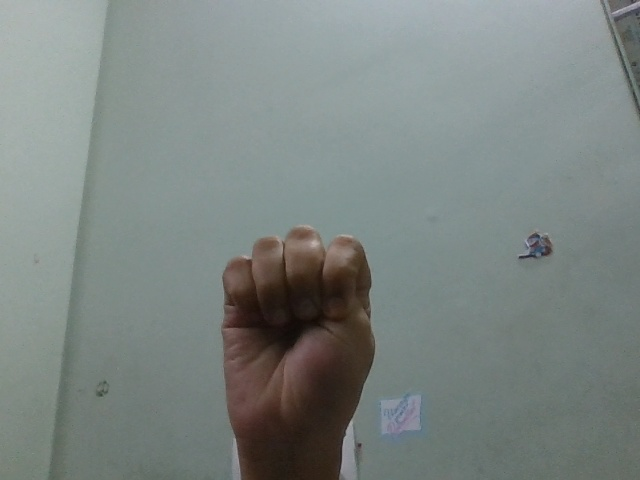

In [18]:
captured_image = capture_asl_image()

display(captured_image)

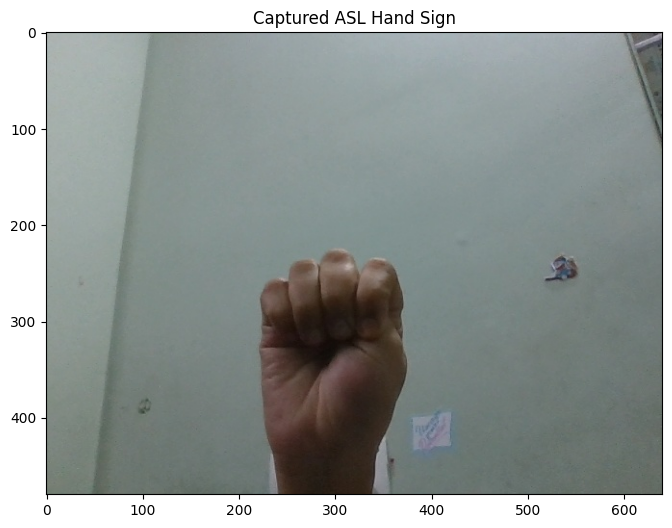

Image size: (640, 480)


In [19]:
import matplotlib.pyplot as plt
from PIL import Image

# Display captured image
plt.figure(figsize=(8, 6))
plt.imshow(captured_image)
plt.axis("on")
plt.title("Captured ASL Hand Sign")
plt.show()

print("Image size:", captured_image.size)

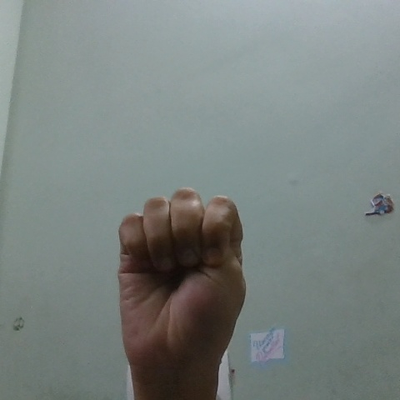

In [20]:
from PIL import ImageOps

# Crop a square region from the center
cropped_hand_new = ImageOps.fit(
    captured_image,
    (400, 400),
    method=Image.Resampling.LANCZOS,
    centering=(0.5, 0.5)
)

display(cropped_hand_new)

In [22]:
import torch
from torchvision import transforms

# Same preprocessing used during training
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

def predict_asl(image):
    image_tensor = preprocess(image.convert("RGB")).unsqueeze(0)
    image_tensor = image_tensor.to("cpu")

    model.eval()

    with torch.no_grad():
        outputs = model(pixel_values=image_tensor)
        probabilities = torch.softmax(outputs.logits, dim=1)

        confidence, predicted_index = torch.max(
            probabilities, dim=1
        )

    predicted_letter = class_names[predicted_index.item()]
    confidence_score = confidence.item() * 100
    print("Actual Letter:M")
    print("Predicted Letter:", predicted_letter)
    print(f"Confidence: {confidence_score:.2f}%")

    return predicted_letter

# Predict your captured hand sign
predicted_letter = predict_asl(cropped_hand_new)

Actual Letter:M
Predicted Letter: E
Confidence: 99.74%


In [ ]:
current_word = ""

def add_letter(letter):
    global current_word

    if letter == "del":
        current_word = current_word[:-1]
    elif letter == "space":
        current_word += " "
    elif letter == "nothing":
        pass
    elif letter in "ABCDEFGHIJKLMNOPQRSTUVWXYZ":
        current_word += letter

    print("Current Word:", current_word)

def delete_last_letter():
    global current_word
    current_word = current_word[:-1]
    print("Current Word:", current_word)

def finish_word():
    global current_word
    print("Completed Word:", current_word)
    return current_word

def clear_word():
    global current_word
    current_word = ""
    print("Word cleared.")

In [ ]:
clear_word()

Word cleared.


<IPython.core.display.Javascript object>

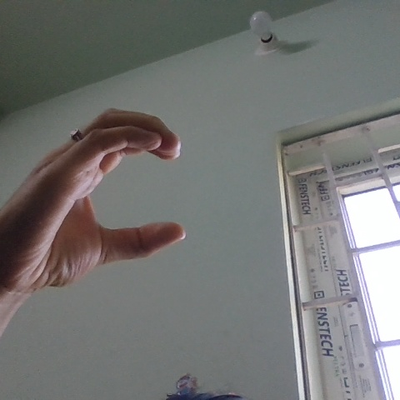

Predicted Letter: C
Confidence: 99.51%
Current Word: C


In [ ]:
captured_image = capture_asl_image()

cropped_hand_new = ImageOps.fit(
    captured_image,
    (400, 400),
    method=Image.Resampling.LANCZOS
)

display(cropped_hand_new)

predicted_letter = predict_asl(cropped_hand_new)
add_letter(predicted_letter)

<IPython.core.display.Javascript object>

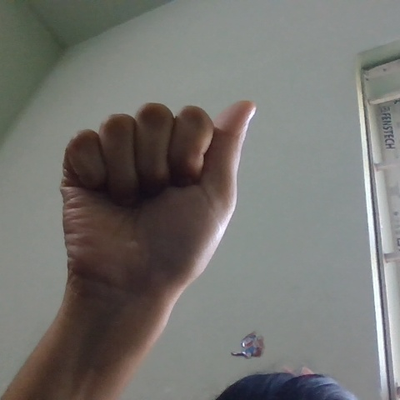

Predicted Letter: A
Confidence: 70.35%
Current Word: CA


In [ ]:
captured_image = capture_asl_image()

cropped_hand_new = ImageOps.fit(
    captured_image,
    (400, 400),
    method=Image.Resampling.LANCZOS
)

display(cropped_hand_new)

predicted_letter = predict_asl(cropped_hand_new)
add_letter(predicted_letter)

<IPython.core.display.Javascript object>

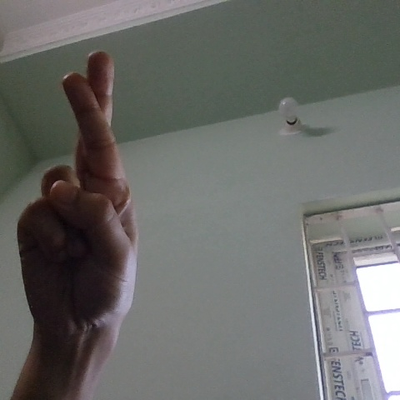

Predicted Letter: R
Confidence: 98.96%
Current Word: CAR


In [ ]:
captured_image = capture_asl_image()

cropped_hand_new = ImageOps.fit(
    captured_image,
    (400, 400),
    method=Image.Resampling.LANCZOS
)

display(cropped_hand_new)

predicted_letter = predict_asl(cropped_hand_new)
add_letter(predicted_letter)

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
import json

def speak_word():
    word = current_word.strip()

    if not word:
        print("No word available. Please form a word first.")
        return

    print("Speaking:", word)

    display(Javascript("""
    window.speakASLWord = function(text) {
        window.speechSynthesis.cancel();

        const speech = new SpeechSynthesisUtterance(text);
        speech.lang = "en-US";
        speech.rate = 0.85;

        window.speechSynthesis.speak(speech);
    };
    """))

    eval_js(f"speakASLWord({json.dumps(word)})")

In [ ]:
print("Completed Word:", current_word)
speak_word()

Completed Word: CAR
Speaking: CAR


<IPython.core.display.Javascript object>